<a href="https://colab.research.google.com/github/Jeffrey-Huber/Predicting-Wildfire-Occurrence-Across-California/blob/main/STAT585_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STAT 585 Project 2

Authors: Jiovanny Alejos, Jeffrey Huber, Sofia Kamage, Nathan Reyes

Research Question:

Real World Significance:

## Part 1: Importing and Setup

In [ ]:
from google.colab import drive

import pandas as pd
import numpy as np
from numpy import astype
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import xarray as xr
from pathlib import Path
import requests
import concurrent.futures

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/stat585/585_project2/National_USFS_Fire_Occurrence_Point_(Feature_Layer).csv'
USFS_df = pd.read_csv(file_path)

USFS_df.head()

/tmp/ipykernel_1441/297457487.py:2: DtypeWarning: Columns (5,8,11,12,13,19) have mixed types. Specify dtype option on import or set low_memory=False.
  USFS_df = pd.read_csv(file_path)


,X,Y,objectid,globalid,fireoccurid,cn,revdate,firename,complexname,fireyear,...,latdd83,longdd83,firetypecategory,pointtype,perimexists,firerptqc,dbsourceid,dbsourcedate,accuracy,shape
0,-111.024021,40.482165,26843158,{B43A7E31-BFD2-4D4A-92CC-678E8573B768},NaN,NaN,2017/02/23 00:00:00+00,Wolf Creek Car,NaN,2000.0,...,40.48217,-111.02402,WF,Ignition,N,No,419,2026/05/18 05:28:12+00,NaN,NaN
1,-111.305733,40.002738,26843159,{328D0475-1A62-4715-9745-69719CB87184},NaN,NaN,2017/02/23 00:00:00+00,Mogbeck 1,NaN,2000.0,...,40.00274,-111.30573,WF,Ignition,N,No,419,2026/05/18 05:28:12+00,NaN,NaN
2,-111.305733,40.002738,26843160,{EA3F4EDC-7BB3-41F9-A9E0-7F7D087105AB},NaN,NaN,2017/02/23 00:00:00+00,Mogbeck 3,NaN,2000.0,...,40.00274,-111.30573,WF,Ignition,N,No,419,2026/05/18 05:28:12+00,NaN,NaN
3,-111.305435,40.003564,26843161,{E4713E62-A934-40E8-A6B7-EC453648037E},NaN,NaN,2017/02/23 00:00:00+00,Mogbeck 2,NaN,2000.0,...,40.00356,-111.30544,WF,Ignition,N,No,419,2026/05/18 05:28:12+00,NaN,NaN
4,-111.188425,40.177737,26843162,{FE9225AB-A5E2-4E24-A9D7-E29E74B95342},NaN,NaN,2017/02/23 00:00:00+00,Bryant Fork Lot 35,NaN,2000.0,...,40.17774,-111.18843,WF,Ignition,N,No,419,2026/05/18 05:28:12+00,NaN,NaN


## Step 2: Investigate Target Dataset

In [ ]:
USFS_df.shape

(573500, 35)

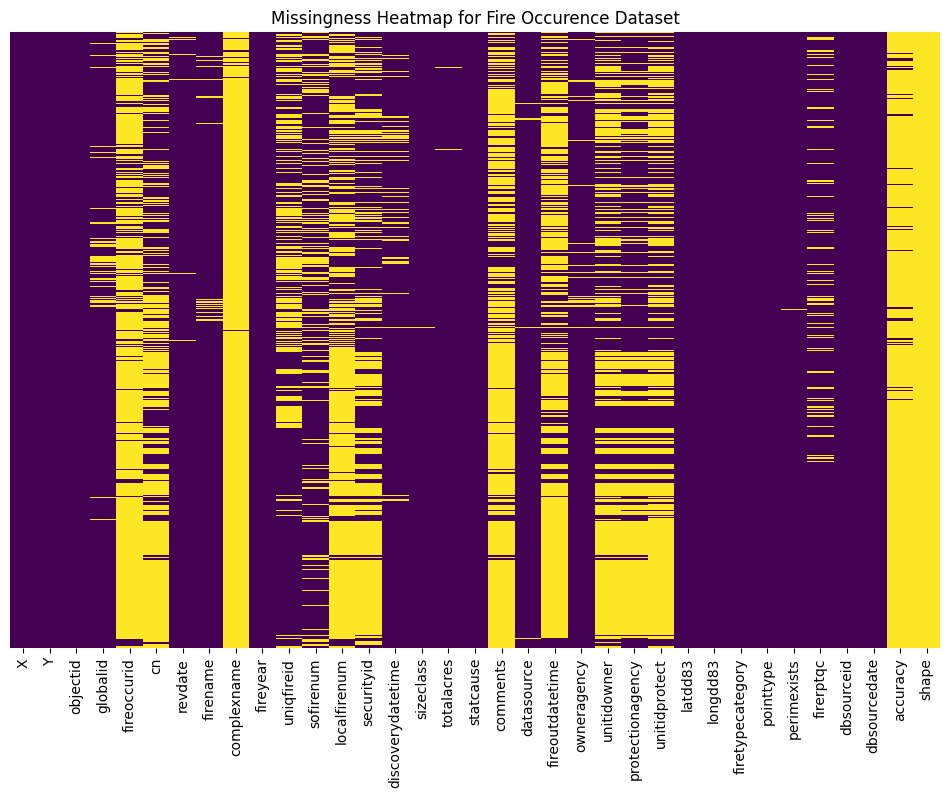

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(USFS_df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missingness Heatmap for Fire Occurence Dataset')
plt.show()

In [ ]:
USFS_df_clean = USFS_df.dropna(axis=1, thresh= int(0.1 * len(USFS_df)))
USFS_df_clean.columns

Index(['X', 'Y', 'objectid', 'globalid', 'fireoccurid', 'cn', 'revdate',
       'firename', 'fireyear', 'uniqfireid', 'sofirenum', 'localfirenum',
       'securityid', 'discoverydatetime', 'sizeclass', 'totalacres',
       'statcause', 'comments', 'datasource', 'fireoutdatetime', 'owneragency',
       'unitidowner', 'protectionagency', 'unitidprotect', 'latdd83',
       'longdd83', 'firetypecategory', 'pointtype', 'perimexists', 'firerptqc',
       'dbsourceid', 'dbsourcedate'],
      dtype='object')

In [ ]:
USFS_df_clean = USFS_df_clean[['firename', 'fireyear', 'discoverydatetime', 'totalacres', 'statcause',
                              'latdd83', 'longdd83']]

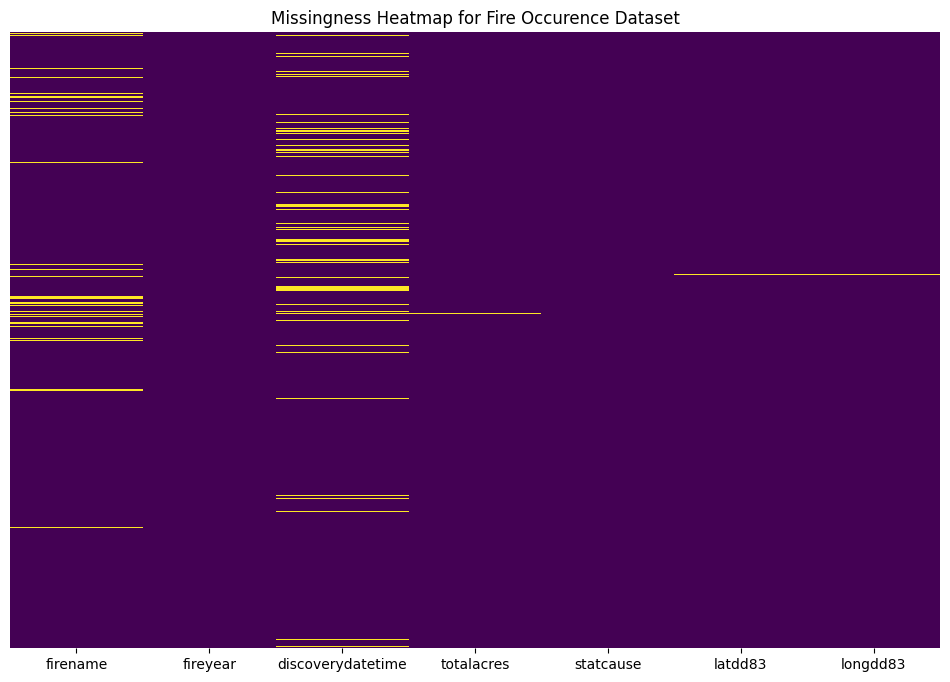

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(USFS_df_clean.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missingness Heatmap for Fire Occurence Dataset')
plt.show()

In [ ]:
# Ensure we have clean fire dates in our clean dataset
USFS_df_clean['fire_date'] = pd.to_datetime(
    USFS_df_clean['discoverydatetime'],
    errors='coerce',
    utc=True
).dt.tz_localize(None).dt.normalize()

USFS_df_clean['year'] = USFS_df_clean['fire_date'].dt.year.astype('Int32')

# Filter for realistic fire years
USFS_df_filtered = USFS_df_clean[
    USFS_df_clean['year'].between(2000, 2024)
].dropna(subset=['longdd83', 'latdd83', 'fire_date', 'year']).copy()

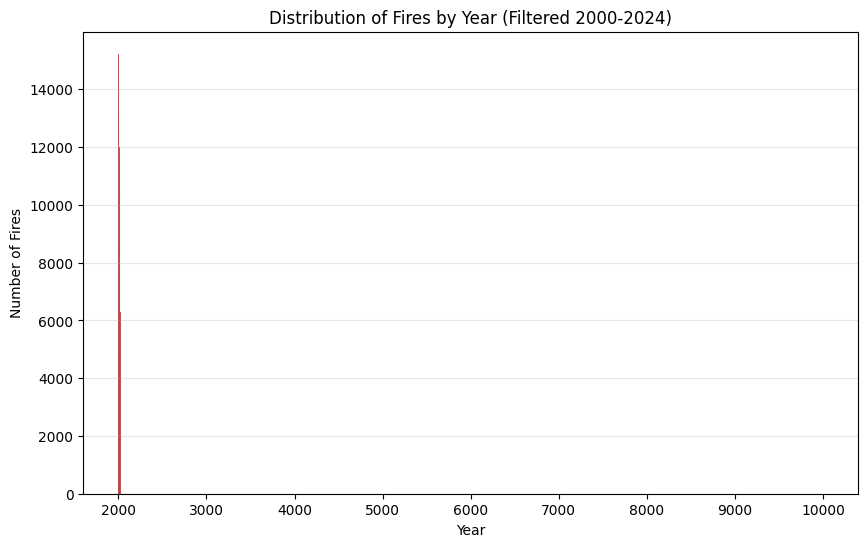

In [ ]:
# Create a histogram of the number of fires by year
plt.figure(figsize=(10, 6))
sns.histplot(data=USFS_df_filtered, x='fireyear', bins=int(USFS_df_filtered['fireyear'].max() - USFS_df_filtered['fireyear'].min() + 1), color='firebrick')
plt.title('Distribution of Fires by Year (Filtered 2000-2024)')
plt.xlabel('Year')
plt.ylabel('Number of Fires')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [ ]:
# Calculate and display the fire counts per cause
cause_counts = USFS_df_clean['statcause'].value_counts().reset_index()
cause_counts.columns = ['Cause', 'Fire Count']

# Display the results
display(cause_counts)

,Cause,Fire Count
0,Lightning,229992
1,Undetermined,98659
2,Camping,56271
3,Equipment,49190
4,Incendiary,39036
5,Debris/Open Burning,28054
6,Other Human Cause,26707
7,Smoking,16687
8,9,6240
9,7,5227


In [ ]:
# Define a mapping dictionary to consolidate and clean the 'statcause' labels
cause_mapping = {
    'Lightning': 'Lightning',
    'Natural': 'Lightning',
    '1': 'Lightning',
    'Other Natural Cause': 'Other Natural',
    'Coal Seam': 'Other Natural',
    'Camping': 'Campfire/Camping',
    'Camping ': 'Campfire/Camping',
    'Campfire': 'Campfire/Camping',
    'Equipment': 'Equipment Use',
    'Equipment Use': 'Equipment Use',
    'Incendiary': 'Arson/Incendiary',
    'Arson': 'Arson/Incendiary',
    'Debris/Open Burning': 'Debris Burning',
    'Debris Burning': 'Debris Burning',
    'Other Human Cause': 'Other Human',
    'Human': 'Other Human',
    'Children': 'Other Human',
    'Smoking': 'Smoking',
    'Railroad': 'Railroad',
    'Utilities': 'Utilities',
    'Firearms/Weapons': 'Firearms/Weapons',
    'Firearms/Weapons ': 'Firearms/Weapons',
    'Undetermined': 'Undetermined/Unknown',
    'Undertermined': 'Undetermined/Unknown',
    'Cause not Identified': 'Undetermined/Unknown',
    'Investigated But Und': 'Undetermined/Unknown',
    'Miscellaneous': 'Miscellaneous/Other',
    '9 - Miscellaneous': 'Miscellaneous/Other',
    '2': 'Equipment Use',
    '3': 'Smoking',
    '4': 'Campfire/Camping',
    '5': 'Debris Burning',
    '6': 'Railroad',
    '7': 'Arson/Incendiary',
    '8': 'Other Human',
    '9': 'Miscellaneous/Other',
    '12': 'Miscellaneous/Other'
}

# Strip whitespaces and map categories
USFS_df_clean['statcause_clean'] = USFS_df_clean['statcause'].astype(str).str.strip().map(cause_mapping).fillna('Other/Unknown')

# Calculate and display the consolidated counts
consolidated_counts = USFS_df_clean['statcause_clean'].value_counts().reset_index()
consolidated_counts.columns = ['Consolidated Cause', 'Count']
consolidated_counts

,Consolidated Cause,Count
0,Lightning,235175
1,Undetermined/Unknown,98664
2,Campfire/Camping,57573
3,Equipment Use,49953
4,Arson/Incendiary,44282
5,Debris Burning,29424
6,Other Human,27896
7,Smoking,17189
8,Miscellaneous/Other,6560
9,Railroad,3173


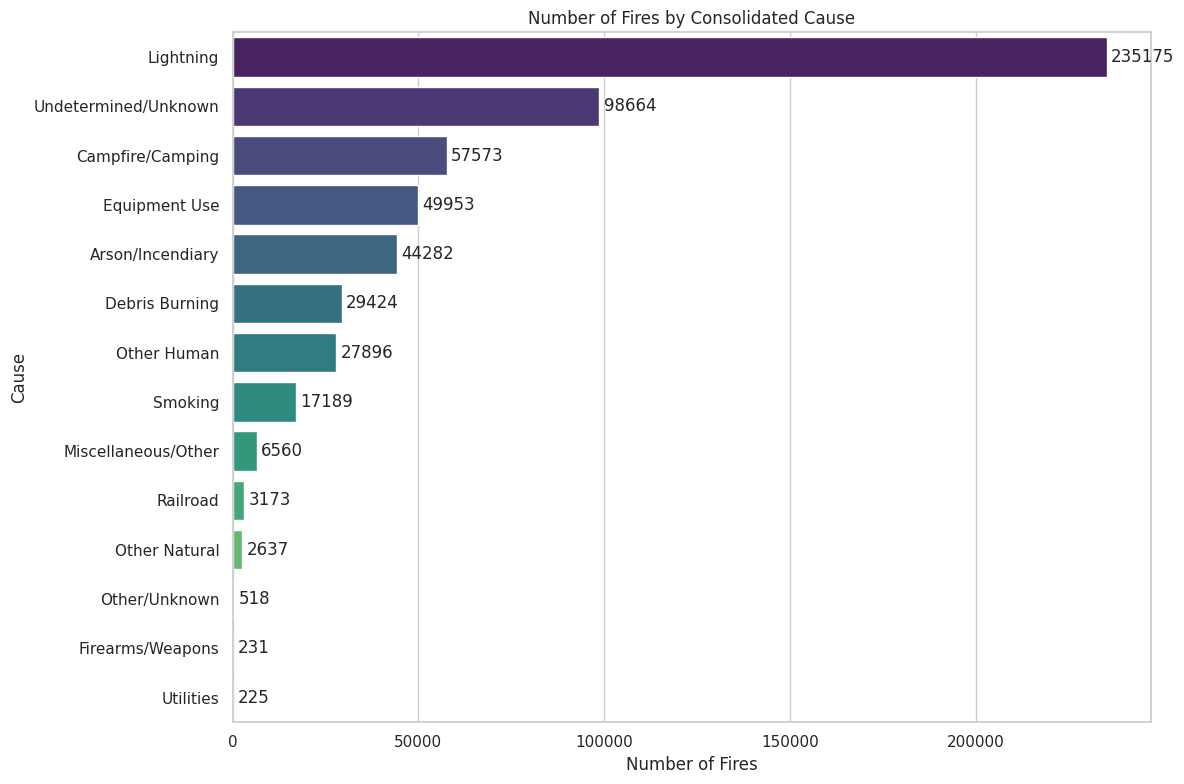

In [ ]:
# Set style
sns.set_theme(style="whitegrid")

# Create a horizontal bar chart for consolidated fire causes
plt.figure(figsize=(12, 8))
ax = sns.barplot(
    data=consolidated_counts,
    x='Count',
    y='Consolidated Cause',
    hue='Consolidated Cause',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Number of Fires by Consolidated Cause')
plt.xlabel('Number of Fires')
plt.ylabel('Cause')
plt.tight_layout()
plt.show()

In [ ]:
USFS_points = gpd.GeoDataFrame(
    USFS_df_clean,
    geometry=gpd.points_from_xy(
        USFS_df_clean["longdd83"],
        USFS_df_clean["latdd83"]
    ),
    crs="EPSG:4326"
)

california_url = (
    "https://raw.githubusercontent.com/johan/world.geo.json/"
    "master/countries/USA/CA.geo.json"
)

california_boundary = gpd.read_file(california_url)

df_cali = gpd.sjoin(
    USFS_points,
    california_boundary,
    predicate="within"
)

df_cali.drop(columns="geometry").to_csv(
    "california_points.csv",
    index=False
)

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

def generate_spatiotemporal_pseudo_absences(presence_df, boundary_gdf, ratio=1.0, seed=42):
    """
    Generates pseudo-absences (non-fire events) within the spatial boundary of California
    and matching the temporal distribution of the presence (fire) events.

    Parameters:
    - presence_df: DataFrame containing the fire incidents (must have 'fire_date' or 'discoverydatetime')
    - boundary_gdf: GeoDataFrame containing the California boundary
    - ratio: Ratio of pseudo-absences to presences (1.0 means equal 50/50 balance)
    """
    np.random.seed(seed)
    num_presences = len(presence_df)
    num_absences = int(num_presences * ratio)

    # Get spatial bounds of California
    minx, miny, maxx, maxy = boundary_gdf.total_bounds

    # Sample random dates matching the distribution of actual fire years/months
    # to preserve seasonality and temporal structures
    available_dates = presence_df['fire_date'].dropna().values
    sampled_dates = np.random.choice(available_dates, size=num_absences, replace=True)

    # Generate random points within California
    points = []
    while len(points) < num_absences:
        # Generate a batch of candidate points
        batch_size = (num_absences - len(points)) * 2
        random_lons = np.random.uniform(minx, maxx, batch_size)
        random_lats = np.random.uniform(miny, maxy, batch_size)
        candidates = gpd.GeoDataFrame(
            geometry=gpd.points_from_xy(random_lons, random_lats),
            crs=boundary_gdf.crs
        )

        # Filter points inside California boundary
        inside_points = gpd.sjoin(candidates, boundary_gdf, predicate='within')
        points.extend(inside_points.geometry.values)

    # Keep only required number of points
    points = points[:num_absences]

    # Assemble the pseudo-absence dataframe
    absences_df = pd.DataFrame({
        'longdd83': [p.x for p in points],
        'latdd83': [p.y for p in points],
        'fire_date': sampled_dates,
        'fire': 0
    })

    # Format output
    absences_df['year'] = pd.to_datetime(absences_df['fire_date']).dt.year
    return absences_df

# 2. Generate pseudo-absences with a 1:1 ratio matching the 2000-2024 timeframe
pseudo_absences = generate_spatiotemporal_pseudo_absences(USFS_df_filtered, california_boundary, ratio=1.0)

# 3. Mark actual fire records with target label 1
fires_labeled = USFS_df_filtered[['longdd83', 'latdd83', 'fire_date', 'year']].copy()
fires_labeled['fire'] = 1

# 4. Concatenate presences and pseudo-absences into a single balanced observation matrix
balanced_observation_matrix = pd.concat([fires_labeled, pseudo_absences], ignore_index=True)

print("Balanced Dataset Shape (2000-2024):", balanced_observation_matrix.shape)
print("Class Distribution:\n", balanced_observation_matrix['fire'].value_counts())

Balanced Dataset Shape (2000-2024): (523650, 5)
Class Distribution:
 fire
1    261825
0    261825
Name: count, dtype: int64


## Step 3: Add Weather Variables

Seed zones

In [ ]:
gdf = gpd.read_file("/content/drive/MyDrive/stat585/585_project2/California_Seed_Zones.geojson")

# Ensure both GeoDataFrames use the same Coordinate Reference System (CRS)
california_points_projected = df_cali.to_crs(gdf.crs)

# Drop the existing 'index_right' column if it exists to prevent join conflicts
if 'index_right' in california_points_projected.columns:
    california_points_projected = california_points_projected.drop(columns='index_right')

# Perform the spatial join to find which seed zone polygon contains each fire point
joined_points = gpd.sjoin(
    california_points_projected,
    gdf[['SEED_ZONE', 'geometry']],
    how='left',
    predicate='within'
)

# Assign the result back to our main california_points DataFrame
df_cali['Seed_Zone'] = joined_points['SEED_ZONE']

# Display the value counts of the newly mapped Seed Zones
display(df_cali['Seed_Zone'].value_counts(dropna=False).head(15))

,count
Seed_Zone,
963,13434
962,13201
996,11962
525,10815
998,9710
526,7741
994,6442
531,6418
961,6262


In [ ]:
# Map GridMET variable names to their OpenDAP URL structures
gridmet_urls = {
    'tmmx_max_temp': 'tmmx',
    'tmmn_min_temp': 'tmmn',
    'vs_wind_speed': 'vs',
    'pr_rain': 'pr',
    'rmax_max_humidity': 'rmax',
    'surface_rad': 'srad',
    'vapor_pressure': 'vpd',
    'enery_release': 'erc'
}

In [ ]:
fires = df_cali.copy()

# Use the fire discovery date
fires["fire_date"] = (
    pd.to_datetime(
        fires["discoverydatetime"],
        errors="coerce",
        utc=True
    )
    .dt.tz_localize(None)
    .dt.normalize()
)

fires = fires[
    fires["fire_date"].dt.year.between(2000, 2025)
].copy()

fires["year"] = fires["fire_date"].dt.year

DATA_FOLDER = Path("/drive/MyDrive/stat585/585_project2/gridmet_data")
DATA_FOLDER.mkdir(exist_ok=True, parents=True)

BASE_URL = "https://www.northwestknowledge.net/metdata/data"

VARIABLES = ["tmmx", "tmmn", "pr", "vs", "rmin", "srad", "vpd", "fm1000", "erc"]

In [ ]:
def download_gridmet_file(variable, year):
    filename = f"{variable}_{year}.nc"
    filepath = DATA_FOLDER / filename

    if filepath.exists():
        print(f"Already downloaded: {filename}")
        return filepath

    url = f"{BASE_URL}/{filename}"
    temporary_path = DATA_FOLDER / f"{filename}.part"

    print(f"Downloading {filename}...")

    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(temporary_path, "wb") as file:
        for chunk in response.iter_content(
            chunk_size=1024 * 1024
        ):
            if chunk:
                file.write(chunk)

    expected_size = response.headers.get("Content-Length")

    if expected_size is not None:
        actual_size = temporary_path.stat().st_size

        if actual_size != int(expected_size):
            temporary_path.unlink()
            raise RuntimeError(
                f"Incomplete download: {filename}"
            )

    temporary_path.rename(filepath)

In [ ]:
# Download 1999 through 2025
for variable in VARIABLES:
    for year in range(1999, 2026):
        download_gridmet_file(variable, year)

In [ ]:
def get_data_variable(dataset):
    for variable in  dataset.data_vars:
        if variable != "crs":
            return variable

    raise ValueError("Could not find the climate variable.")

In [ ]:
def load_small_gridmet_area(
    variable,
    year,
    fire_dates,
    fire_lats,
    fire_lons
):
    """
    Loads only:
    - the previous/current year
    - the date range needed
    - the geographic area around the fires
    """

    start_date = (
        fire_dates.min() - pd.Timedelta(days=90)
    )
    end_date = fire_dates.max()

    # Add a small buffer so nearest-cell selection works
    lat_min = fire_lats.min() - 0.1
    lat_max = fire_lats.max() + 0.1
    lon_min = fire_lons.min() - 0.1
    lon_max = fire_lons.max() + 0.1

    pieces = []

    for file_year in [year - 1, year]:

        filepath = (
            DATA_FOLDER /
            f"{variable}_{file_year}.nc"
        )

        ds = xr.open_dataset(
            filepath,
            engine="h5netcdf"
        )

        variable_name = get_data_variable(ds)

        file_start = pd.Timestamp(
            f"{file_year}-01-01"
        )
        file_end = pd.Timestamp(
            f"{file_year}-12-31"
        )

        subset_start = max(start_date, file_start)
        subset_end = min(end_date, file_end)

        if subset_start <= subset_end:

            subset = ds[variable_name].sel(
                day=slice(
                    subset_start,
                    subset_end
                ),
                lat=slice(
                    lat_max,
                    lat_min
                ),
                lon=slice(
                    lon_min,
                    lon_max
                )
            ).load()

            pieces.append(subset)

        ds.close()

    combined = xr.concat(
        pieces,
        dim="day"
    ).sortby("day")

    return combined

In [ ]:
for year, indexes in fires.groupby("year").groups.items():

    print(f"Processing {year}")

    fire_dates = fires.loc[
        indexes, "fire_date"
    ]

    fire_lats = fires.loc[
        indexes, "latdd83"
    ].to_numpy()

    fire_lons = fires.loc[
        indexes, "longdd83"
    ].to_numpy()

    fire_dates_xr = xr.DataArray(
        fire_dates.to_numpy(
            dtype="datetime64[ns]"
        ),
        dims="fire"
    )

    fire_lats_xr = xr.DataArray(
        fire_lats,
        dims="fire"
    )

    fire_lons_xr = xr.DataArray(
        fire_lons,
        dims="fire"
    )

    # -------------------------
    # Maximum temperature
    # -------------------------

    tmmx = load_small_gridmet_area(
        "tmmx",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    tmmx_points = tmmx.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "tmmx_fire_day"] = (
        tmmx_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[indexes, "tmmx_previous_7_day_mean"] = (
        tmmx_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del tmmx
    del tmmx_points

    # -------------------------
    # Minimum temperature
    # -------------------------

    tmmn = load_small_gridmet_area(
        "tmmn",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    tmmn_points = tmmn.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "tmmn_fire_day"] = (
        tmmn_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[indexes, "tmmn_previous_7_day_mean"] = (
        tmmn_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del tmmn
    del tmmn_points

    # -------------------------
    # Precipitation
    # -------------------------

    pr = load_small_gridmet_area(
        "pr",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    pr_points = pr.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    for days, column in [
        (1, "rain_previous_1_day_mm"),
        (7, "rain_previous_7_days_mm"),
        (30, "rain_previous_30_days_mm"),
        (90, "rain_previous_90_days_mm")
    ]:

        fires.loc[indexes, column] = (
            pr_points
            .rolling(day=days, min_periods=days)
            .sum()
            .shift(day=1)
            .sel(day=fire_dates_xr)
            .values
        )

    del pr
    del pr_points

    # -------------------------
    # Wind
    # -------------------------

    vs = load_small_gridmet_area(
        "vs",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    vs_points = vs.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "wind_fire_day"] = (
        vs_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[indexes, "wind_previous_3_day_max"] = (
        vs_points
        .rolling(day=3, min_periods=3)
        .max()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del vs
    del vs_points

    # -------------------------
    # Minimum relative humidity
    # -------------------------

    rmin = load_small_gridmet_area(
        "rmin",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    rmin_points = rmin.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "rmin_fire_day"] = (
        rmin_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[
        indexes,
        "rmin_previous_7_day_mean"
    ] = (
        rmin_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del rmin
    del rmin_points

    # -------------------------
    # Solar radiation
    # -------------------------

    srad = load_small_gridmet_area(
        "srad",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    srad_points = srad.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[
        indexes,
        "srad_previous_7_day_mean"
    ] = (
        srad_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del srad
    del srad_points

    # -------------------------
    # Vapor Pressure Deficit (vpd)
    # -------------------------

    vpd = load_small_gridmet_area(
        "vpd",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    vpd_points = vpd.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "vpd_fire_day"] = (
        vpd_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[
        indexes,
        "vpd_previous_7_day_mean"
    ] = (
        vpd_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del vpd
    del vpd_points

    # -------------------------
    # Energy Release Component (erc)
    # -------------------------

    erc = load_small_gridmet_area(
        "erc",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    erc_points = erc.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "erc_fire_day"] = (
        erc_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[
        indexes,
        "erc_previous_7_day_mean"
    ] = (
        erc_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del erc
    del erc_points

    # -------------------------
    # 1000-hour Fuel Moisture (fm1000)
    # -------------------------

    fm1000 = load_small_gridmet_area(
        "fm1000",
        year,
        fire_dates,
        fire_lats,
        fire_lons
    )

    fm1000_points = fm1000.sel(
        lat=fire_lats_xr,
        lon=fire_lons_xr,
        method="nearest"
    ).transpose("day", "fire")

    fires.loc[indexes, "fm1000_fire_day"] = (
        fm1000_points
        .sel(day=fire_dates_xr)
        .values
    )

    fires.loc[
        indexes,
        "fm1000_previous_7_day_mean"
    ] = (
        fm1000_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
        .sel(day=fire_dates_xr)
        .values
    )

    del fm1000
    del fm1000_points

    print(f"Finished {year}")

Processing 2000
Finished 2000
Processing 2001
Finished 2001
Processing 2002
Finished 2002
Processing 2003
Finished 2003
Processing 2004
Finished 2004
Processing 2005
Finished 2005
Processing 2006
Finished 2006
Processing 2007
Finished 2007
Processing 2008
Finished 2008
Processing 2009
Finished 2009
Processing 2010
Finished 2010
Processing 2011
Finished 2011
Processing 2012
Finished 2012
Processing 2013
Finished 2013
Processing 2014
Finished 2014
Processing 2015
Finished 2015
Processing 2016
Finished 2016
Processing 2017
Finished 2017
Processing 2018
Finished 2018
Processing 2019
Finished 2019
Processing 2020
Finished 2020
Processing 2021
Finished 2021
Processing 2022
Finished 2022
Processing 2023
Finished 2023
Processing 2024
Finished 2024
Processing 2025
Finished 2025


In [ ]:
fires["tmmx_fire_day_c"] = (
    fires["tmmx_fire_day"] - 273.15
)

fires["tmmn_fire_day_c"] = (
    fires["tmmn_fire_day"] - 273.15
)

fires["tmmx_previous_7_day_mean_c"] = (
    fires["tmmx_previous_7_day_mean"] - 273.15
)

fires["tmmn_previous_7_day_mean_c"] = (
    fires["tmmn_previous_7_day_mean"] - 273.15
)

In [ ]:
fires

,firename,fireyear,discoverydatetime,totalacres,statcause,latdd83,longdd83,fire_date,year,statcause_clean,...,vpd_fire_day,vpd_previous_7_day_mean,erc_fire_day,erc_previous_7_day_mean,fm1000_fire_day,fm1000_previous_7_day_mean,tmmx_fire_day_c,tmmn_fire_day_c,tmmx_previous_7_day_mean_c,tmmn_previous_7_day_mean_c
8262,GILMAN,2021.0,2021/08/15 18:13:00+00,0.50,Equipment,40.82283,-122.32420,2021-08-15,2021,Equipment Use,...,4.53,3.492857,91.0,90.428571,5.2,5.142857,43.05,23.05,37.778571,20.307143
8264,Lower,2016.0,2016/06/05 19:05:00+00,2.00,Lightning,41.76750,-123.38417,2016-06-05,2016,Lightning,...,2.76,2.284286,60.0,55.571429,11.5,12.528571,38.35,16.25,34.507143,10.964286
8266,Whitaker,2016.0,2016/05/26 17:31:00+00,0.10,Equipment,34.58722,-118.71083,2016-05-26,2016,Equipment Use,...,1.12,0.801429,61.0,60.714286,10.1,9.942857,23.05,11.35,18.064286,8.092857
8268,Scott,2016.0,2016/06/16 15:30:00+00,0.05,Debris/Open Burning,41.71947,-123.02210,2016-06-16,2016,Debris Burning,...,0.67,1.342857,47.0,65.142857,9.6,9.628571,18.35,4.45,24.150000,6.964286
8270,RUTH,2016.0,2016/08/04 03:55:00+00,0.10,Undetermined,40.26367,-123.31850,2016-08-04,2016,Undetermined/Unknown,...,1.81,2.450000,78.0,75.571429,8.2,8.828571,30.15,13.15,32.678571,15.735714
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564780,Snow,2024.0,2024/09/01 19:43:15+00,0.32,Other Natural Cause,34.16367,-116.72700,2024-09-01,2024,Other Natural,...,1.48,1.432857,87.0,90.285714,6.0,6.042857,24.55,9.45,22.092857,7.392857
564781,Worth,2024.0,2024/06/25 01:03:54+00,0.25,Undetermined,34.32093,-118.40361,2024-06-25,2024,Undetermined/Unknown,...,1.09,1.635714,51.0,51.428571,12.2,12.842857,29.05,17.35,29.807143,16.578571
564782,Sloat,2024.0,2024/08/04 19:11:44+00,0.10,Other Natural Cause,39.70949,-120.73517,2024-08-04,2024,Other Natural,...,1.34,1.405714,77.0,79.000000,6.9,6.542857,25.45,11.95,23.792857,10.592857
564783,Board,2024.0,2024/09/05 03:43:00+00,0.70,Undetermined,39.80962,-122.93617,2024-09-05,2024,Undetermined/Unknown,...,2.71,1.938571,78.0,70.428571,8.4,9.057143,29.05,20.15,25.578571,17.035714


TODO: add a visualization about the distribution of gridmet data

## Step 4: Add Vegetation Variables

In [ ]:
# Set the limit to 18,812 to capture all unique coordinate-year locations in the dataset
BATCH_LIMIT = 18812

# Get unique location-years to minimize API overhead
unique_obs = fires[['latdd83', 'longdd83', 'year']].drop_duplicates().copy()
unique_obs['obs_id'] = range(len(unique_obs))

# Slice the unique observations according to our batch limit
query_batch = unique_obs.head(BATCH_LIMIT).copy()

RAP_URL = "https://us-central1-rap-data-365417.cloudfunctions.net/coverV3"

def fetch_rap_fractional_cover(row):
    lat = row["latdd83"]
    lon = row["longdd83"]
    target_year = int(row["year"])

    payload = {
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [lon, lat]},
        "properties": {
            "mask": True,
            "year": None,
        },
    }

    try:
        response = requests.post(RAP_URL, json=payload, timeout=15)
        if response.status_code == 200:
            data = response.json()
            raw_cover = data["properties"]["cover"]
            cover_df = pd.DataFrame(raw_cover[1:], columns=raw_cover[0])
            cover_df = cover_df.apply(pd.to_numeric)

            matched_year = cover_df[cover_df["year"] == target_year]
            if not matched_year.empty:
                result = matched_year.iloc[0].to_dict()
                result["obs_id"] = row["obs_id"]
                return result
    except Exception as e:
        pass
    return None

# Parallel fetching of RAP Cover Data
results_list = []
print(f"Fetching RAP spatial cover for {len(query_batch)} observations...")
with concurrent.futures.ThreadPoolExecutor(max_workers=20) as executor:
    futures = [executor.submit(fetch_rap_fractional_cover, row) for _, row in query_batch.iterrows()]
    for future in concurrent.futures.as_completed(futures):
        res = future.result()
        if res:
            results_list.append(res)

rap_cover_df = pd.DataFrame(results_list)

if not rap_cover_df.empty:
    # Rename columns to standardized descriptive feature names
    rap_cover_df = rap_cover_df.rename(columns={
        'AFG': 'ann_forb_grass',
        'PFG': 'peren_forb_grass',
        'SHR': 'shrub',
        'TRE': 'tree',
        'LTR': 'litter',
        'BGR': 'bare_ground'
    })

    # Drop duplicate 'year' column in rap_cover_df to prevent pandas merge suffixing (_x, _y)
    if 'year' in rap_cover_df.columns:
        rap_cover_df = rap_cover_df.drop(columns=['year'])

    # Merge Cover properties with query coordinates
    queried_results = query_batch.merge(rap_cover_df, on='obs_id', how='inner')

    # Final Join back to matched CALFIRE observation DataFrame
    calfire_with_rap_features_large = pd.merge(
        fires,
        queried_results[['latdd83', 'longdd83', 'year', 'ann_forb_grass', 'peren_forb_grass', 'shrub', 'tree', 'litter', 'bare_ground']],
        on=['latdd83', 'longdd83', 'year'],
        how='inner'
    )

    print(f"Join completed! New shape: {calfire_with_rap_features_large.shape}")
    display(calfire_with_rap_features_large.head())
else:
    print("No RAP data could be fetched for this batch.")

Fetching RAP spatial cover for 18812 observations...
Join completed! New shape: (22653, 45)


,firename,fireyear,discoverydatetime,totalacres,statcause,latdd83,longdd83,fire_date,year,statcause_clean,...,tmmx_fire_day_c,tmmn_fire_day_c,tmmx_previous_7_day_mean_c,tmmn_previous_7_day_mean_c,ann_forb_grass,peren_forb_grass,shrub,tree,litter,bare_ground
0,GILMAN,2021.0,2021/08/15 18:13:00+00,0.50,Equipment,40.82283,-122.32420,2021-08-15,2021,Equipment Use,...,43.05,23.05,37.778571,20.307143,-99,-99,-99,-99,-99,-99
1,Lower,2016.0,2016/06/05 19:05:00+00,2.00,Lightning,41.76750,-123.38417,2016-06-05,2016,Lightning,...,38.35,16.25,34.507143,10.964286,0,0,0,80,2,0
2,Whitaker,2016.0,2016/05/26 17:31:00+00,0.10,Equipment,34.58722,-118.71083,2016-05-26,2016,Equipment Use,...,23.05,11.35,18.064286,8.092857,-99,-99,-99,-99,-99,-99
3,Scott,2016.0,2016/06/16 15:30:00+00,0.05,Debris/Open Burning,41.71947,-123.02210,2016-06-16,2016,Debris Burning,...,18.35,4.45,24.150000,6.964286,3,12,13,37,14,7
4,RUTH,2016.0,2016/08/04 03:55:00+00,0.10,Undetermined,40.26367,-123.31850,2016-08-04,2016,Undetermined/Unknown,...,30.15,13.15,32.678571,15.735714,10,8,17,30,12,7


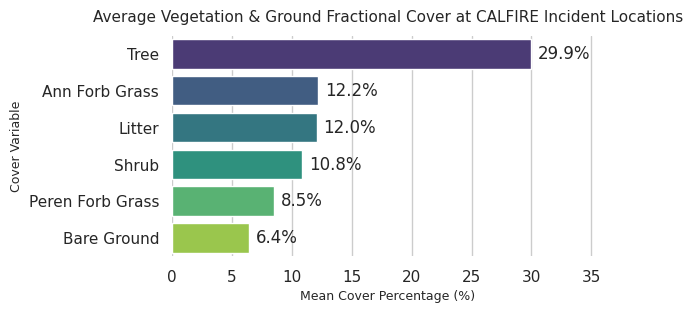

In [ ]:

# List of environmental cover columns imported from RAP
rap_columns = ['ann_forb_grass', 'peren_forb_grass', 'shrub', 'tree', 'litter', 'bare_ground']

# Filter out potential placeholder values (-99 denotes masked/unmapped locations in RAP)
clean_rap_data = calfire_with_rap_features_large[(calfire_with_rap_features_large[rap_columns] >= 0).all(axis=1)]

# Calculate mean percentages for each variable
mean_cover = clean_rap_data[rap_columns].mean().reset_index()
mean_cover.columns = ['Cover Type', 'Mean Percentage']

# Clean names for presentation
mean_cover['Cover Type'] = mean_cover['Cover Type'].str.replace('_', ' ').str.title()

# Sort values from highest to lowest cover
mean_cover = mean_cover.sort_values(by='Mean Percentage', ascending=False)

# Set theme and figure size (more compact height to reduce vertical whitespace)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 3))

# Plot the bar chart
ax = sns.barplot(
    x='Mean Percentage',
    y='Cover Type',
    data=mean_cover,
    palette='viridis',
    hue='Cover Type',
    legend=False
)

# Annotate percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=5)

# Titles & labels (lower vertical padding to reduce whitespace)
plt.title('Average Vegetation & Ground Fractional Cover at CALFIRE Incident Locations', fontsize=11, pad=10)
plt.xlabel('Mean Cover Percentage (%)', fontsize=9)
plt.ylabel('Cover Variable', fontsize=9)

# Adjust x-limit slightly above max percentage (30%) instead of 100% to remove horizontal whitespace
plt.xlim(0, 36)

# Despine and use tight layout to eliminate outer white space
sns.despine(top=True, right=True, left=True, bottom=True)
plt.tight_layout(pad=0.2)
plt.show()

## Step 5: Add Seasonal Risk Factors

In [ ]:
# Define the three fire season categories
# May (5) to October (10) -> Peak
# April (4) and November (11) -> Shoulder
# Others -> Off-season
month = fires['fire_date'].dt.month

fires['fire_season'] = np.select(
    [
        month.between(5, 10),
        month.isin([4, 11])
    ],
    [
        'Peak (May-Oct)',
        'Adjacent (Apr/Nov)'
    ],
    default='Off-season'
)

# Display the value counts of the updated column to verify
display(fires['fire_season'].value_counts(dropna=False))

,count
fire_season,
Peak (May-Oct),109904
Off-season,11108
Adjacent (Apr/Nov),10651


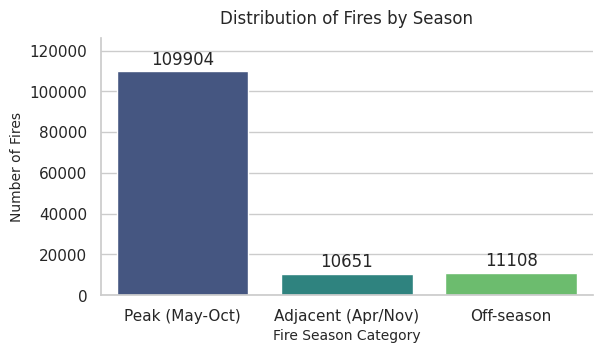

In [ ]:
# Create a count plot for the fire_season variable
plt.figure(figsize=(6, 3.5))
ax = sns.countplot(
    data=fires,
    x='fire_season',
    order=['Peak (May-Oct)', 'Adjacent (Apr/Nov)', 'Off-season'],
    palette='viridis',
    hue='fire_season',
    legend=False
)

# Add count labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=2)

plt.title('Distribution of Fires by Season', fontsize=12, pad=10)
plt.xlabel('Fire Season Category', fontsize=10)
plt.ylabel('Number of Fires', fontsize=10)

# Reduce margins and whitespace
sns.despine(top=True, right=True)
plt.margins(y=0.15)
plt.tight_layout(pad=0.5)
plt.show()

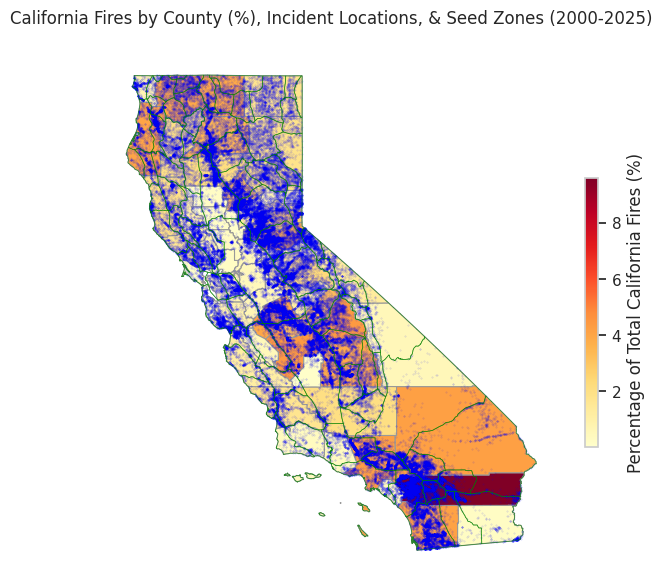

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Fetch California Counties spatial boundary
counties_url = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/california-counties.geojson"
ca_counties = gpd.read_file(counties_url)

# Rename the county name column immediately to avoid conflicts
if 'name' in ca_counties.columns:
    ca_counties = ca_counties.rename(columns={'name': 'county_name'})
elif 'NAME' in ca_counties.columns:
    ca_counties = ca_counties.rename(columns={'NAME': 'county_name'})
else:
    ca_counties = ca_counties.rename(columns={ca_counties.columns[0]: 'county_name'})

# Keep only standard columns
ca_counties = ca_counties[['county_name', 'geometry']]

# 2. Fetch and prepare California Seed Zones
seed_zones = gpd.read_file("/content/drive/MyDrive/stat585/585_project2/California_Seed_Zones.geojson")

# 3. Convert fire incidents into a GeoDataFrame
fire_gdf = gpd.GeoDataFrame(
    fires,
    geometry=gpd.points_from_xy(fires['longdd83'], fires['latdd83']),
    crs="EPSG:4326"
)

# Drop conflicting index columns if they exist
for col in ['index_right', 'county_name']:
    if col in fire_gdf.columns:
        fire_gdf = fire_gdf.drop(columns=col)

# 4. Align Coordinate Reference Systems (CRS)
ca_counties = ca_counties.to_crs(fire_gdf.crs)
seed_zones_aligned = seed_zones.to_crs(fire_gdf.crs)

# 5. Perform spatial join for counties
fires_in_counties = gpd.sjoin(fire_gdf, ca_counties, how="inner", predicate="within")

# 6. Calculate fire counts and percentage of fires per county
county_counts = fires_in_counties['county_name'].value_counts().reset_index()
county_counts.columns = ['county_name', 'fire_count']
total_fires = county_counts['fire_count'].sum()
county_counts['fire_percentage'] = (county_counts['fire_count'] / total_fires) * 100

# 7. Merge percentages back into the counties GeoDataFrame
ca_counties_merged = ca_counties.merge(county_counts, on='county_name', how='left')
ca_counties_merged['fire_percentage'] = ca_counties_merged['fire_percentage'].fillna(0)

# 8. Plotting the map
fig, ax = plt.subplots(figsize=(6, 6))

# Plot choropleth of counties by fire percentage
ca_counties_merged.plot(
    column='fire_percentage',
    cmap='YlOrRd',
    linewidth=0.8,
    ax=ax,
    edgecolor='0.6',
    legend=True,
    legend_kwds={
        'label': 'Percentage of Total California Fires (%)',
        'orientation': 'vertical',
        'shrink': 0.5
    }
)

# Overlay California Seed Zone boundaries
seed_zones_aligned.geometry.boundary.plot(
    ax=ax,
    color='green',
    linewidth=0.5,
    alpha=0.7,
    label='California Seed Zones'
)

# Plot individual fire incidents
fire_gdf.plot(
    ax=ax,
    color='blue',
    markersize=0.1,
    alpha=0.2,
    label='Fire Incidents'
)

# Title and layout details
plt.title('California Fires by County (%), Incident Locations, & Seed Zones (2000-2025)', fontsize=12, pad=20)
ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Group by both county and seed zone using the spatially joined dataset
county_seed_summary = fires_in_counties.groupby(['county_name', 'Seed_Zone'], dropna=False).agg(
    fire_count=('firename', 'count'),
    average_acres=('totalacres', 'mean')
).reset_index()

# Calculate percentages of total fires
total_fires_mapped = county_seed_summary['fire_count'].sum()
county_seed_summary['percentage_of_total'] = (county_seed_summary['fire_count'] / total_fires_mapped) * 100

# Sort by count descending
county_seed_summary = county_seed_summary.sort_values(by='fire_count', ascending=False).reset_index(drop=True)

# Display top 20 combinations
display(county_seed_summary.head(20))

,county_name,Seed_Zone,fire_count,average_acres,percentage_of_total
0,Riverside,996,6405,17.861088,4.868020
1,San Diego,998,5056,187.185196,3.842734
2,El Dorado,526,4245,82.533312,3.226346
3,Merced,962,4224,10.906012,3.210385
4,Humboldt,303,3339,20.913890,2.537755
5,San Bernardino,994,3199,120.126834,2.431350
6,Fresno,963,3134,6.699627,2.381948
7,Madera,963,2704,6.701890,2.055133
8,Tuolumne,531,2562,148.691671,1.947208
9,Los Angeles,993,2505,219.689693,1.903886


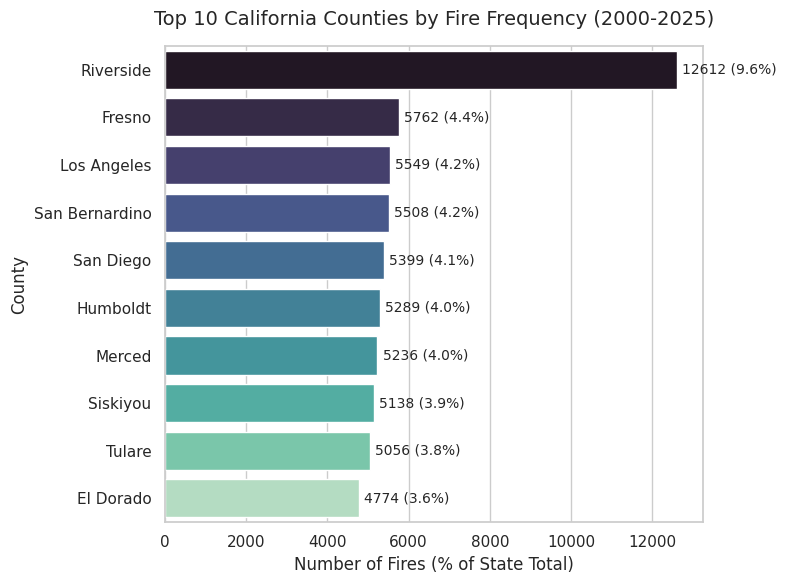

In [ ]:
# Group by county and calculate total fire counts using the spatially joined dataset
county_freq = fires_in_counties.groupby('county_name').size().reset_index(name='Fire Count')
county_freq = county_freq.dropna(subset=['county_name'])

# Calculate total mapped fires to get percentage labels
total_mapped_fires = county_freq['Fire Count'].sum()
county_freq['Percentage'] = (county_freq['Fire Count'] / total_mapped_fires) * 100

# Get top 10 counties by frequency
top_10_freq = county_freq.sort_values(by='Fire Count', ascending=False).head(10)

# Create the visualization
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    data=top_10_freq,
    x='Fire Count',
    y='county_name',
    palette='mako',
    hue='county_name',
    legend=False
)

# Safely annotate the bars with fire counts and percentages
for i, bar in enumerate(ax.patches):
    # Get width (value) of the current bar
    width = bar.get_width()
    if width > 0:  # Only label visible bars
        # Locate corresponding row values in our sorted DataFrame
        row = top_10_freq.iloc[i]
        label = f"{int(row['Fire Count'])} ({row['Percentage']:.1f}%)"

        # Place text at the end of each bar
        ax.text(
            width + (max(top_10_freq['Fire Count']) * 0.01),
            bar.get_y() + bar.get_height() / 2,
            label,
            va='center',
            ha='left',
            fontsize=10
        )

plt.title('Top 10 California Counties by Fire Frequency (2000-2025)', fontsize=14, pad=15)
plt.xlabel('Number of Fires (% of State Total)', fontsize=12)
plt.ylabel('County', fontsize=12)
plt.tight_layout()
plt.show()

## Step 6 Modeling

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import box

GRID_SIZE = 0.05

# Combine California boundary geometry
ca_polygon = california_boundary.geometry.unary_union

min_lon, min_lat, max_lon, max_lat = ca_polygon.bounds

# Align grid boundaries to GRID_SIZE
lon_values = np.arange(
    np.floor(min_lon / GRID_SIZE) * GRID_SIZE,
    max_lon,
    GRID_SIZE
)

lat_values = np.arange(
    np.floor(min_lat / GRID_SIZE) * GRID_SIZE,
    max_lat,
    GRID_SIZE
)

grid_records = []

for lon in lon_values:
    for lat in lat_values:

        cell = box(
            lon,
            lat,
            lon + GRID_SIZE,
            lat + GRID_SIZE
        )

        # Keep cells whose center lies in California
        if ca_polygon.contains(cell.centroid):
            grid_records.append({
                'grid_lon': round(lon + GRID_SIZE / 2, 4),
                'grid_lat': round(lat + GRID_SIZE / 2, 4),
                'geometry': cell
            })

california_grid = gpd.GeoDataFrame(
    grid_records,
    crs='EPSG:4326'
)

california_grid['cell_id'] = range(
    len(california_grid)
)

print("California cells:", len(california_grid))
display(california_grid.head())

/tmp/ipykernel_1441/387581568.py:9: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  ca_polygon = california_boundary.geometry.unary_union


California cells: 16657


,grid_lon,grid_lat,geometry,cell_id
0,-124.375,40.325,"POLYGON ((-124.35 40.3, -124.35 40.35, -124.4 ...",0
1,-124.375,40.375,"POLYGON ((-124.35 40.35, -124.35 40.4, -124.4 ...",1
2,-124.375,40.425,"POLYGON ((-124.35 40.4, -124.35 40.45, -124.4 ...",2
3,-124.375,40.475,"POLYGON ((-124.35 40.45, -124.35 40.5, -124.4 ...",3
4,-124.325,40.275,"POLYGON ((-124.3 40.25, -124.3 40.3, -124.35 4...",4


In [ ]:
years = pd.DataFrame({
    'year': range(2000, 2026)
})

grid_years = california_grid[
    ['cell_id', 'grid_lat', 'grid_lon']
].merge(
    years,
    how='cross'
)

print("Expected cell-year observations:", len(grid_years))

Expected cell-year observations: 433082


In [ ]:
fire_points = gpd.GeoDataFrame(
    fires[['latdd83', 'longdd83', 'year']].copy(),
    geometry=gpd.points_from_xy(
        fires['longdd83'],
        fires['latdd83']
    ),
    crs='EPSG:4326'
)

In [ ]:
fire_points_with_cells = gpd.sjoin(
    fire_points,
    california_grid[
        ['cell_id', 'geometry']
    ],
    how='inner',
    predicate='within'
)

In [ ]:
fire_labels = (
    fire_points_with_cells[
        ['cell_id', 'year']
    ]
    .drop_duplicates()
)

fire_labels['fire'] = 1

In [ ]:
location_model_data = grid_years.merge(
    fire_labels,
    on=['cell_id', 'year'],
    how='left'
)

location_model_data['fire'] = (
    location_model_data['fire']
    .fillna(0)
    .astype(int)
)

print(location_model_data.shape)
print(location_model_data['fire'].value_counts())

(433082, 5)
fire
0    369404
1     63678
Name: count, dtype: int64


In [ ]:
grid_centers = california_grid[
    ['cell_id', 'geometry']
].copy()

grid_centers['geometry'] = (
    grid_centers.geometry.representative_point()
)

In [ ]:
seed_zones = gdf.to_crs('EPSG:4326')

In [ ]:
grid_seed_zones = gpd.sjoin(
    grid_centers,
    seed_zones[
        ['SEED_ZONE', 'geometry']
    ],
    how='left',
    predicate='within'
)

grid_seed_zones = grid_seed_zones[
    ['cell_id', 'SEED_ZONE']
].rename(
    columns={'SEED_ZONE': 'Seed_Zone'}
)

In [ ]:
location_model_data = location_model_data.merge(
    grid_seed_zones,
    on='cell_id',
    how='left'
)

In [ ]:
expected_rows = (
    len(california_grid) * len(years)
)

actual_rows = len(location_model_data)

print("Expected rows:", expected_rows)
print("Actual rows:", actual_rows)

print(
    "Duplicate cell-years:",
    location_model_data
    .duplicated(['cell_id', 'year'])
    .sum()
)

Expected rows: 433082
Actual rows: 433082
Duplicate cell-years: 0


In [ ]:
location_model_data

,cell_id,grid_lat,grid_lon,year,fire,Seed_Zone
0,0,40.325,-124.375,2000,0,NaN
1,0,40.325,-124.375,2001,0,NaN
2,0,40.325,-124.375,2002,0,NaN
3,0,40.325,-124.375,2003,0,NaN
4,0,40.325,-124.375,2004,0,NaN
...,...,...,...,...,...,...
433077,16656,34.325,-114.175,2021,0,983
433078,16656,34.325,-114.175,2022,0,983
433079,16656,34.325,-114.175,2023,0,983
433080,16656,34.325,-114.175,2024,0,983


In [ ]:
RAP_URL = (
    "https://us-central1-rap-data-365417"
    ".cloudfunctions.net/coverV3"
)

rap_features = [
    'ann_forb_grass',
    'peren_forb_grass',
    'shrub',
    'tree',
    'litter',
    'bare_ground'
]

# Query one point per grid cell.
# The API returns all available years for that point.
rap_query = california_grid[
    ['cell_id', 'grid_lat', 'grid_lon']
].copy()

def fetch_rap_all_years(row):

    payload = {
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [
                row['grid_lon'],
                row['grid_lat']
            ]
        },
        "properties": {
            "mask": True,
            "year": None
        }
    }

    try:
        response = requests.post(
            RAP_URL,
            json=payload,
            timeout=10
        )

        if response.status_code != 200:
            return []

        data = response.json()
        raw_cover = data["properties"]["cover"]

        cover_df = pd.DataFrame(
            raw_cover[1:],
            columns=raw_cover[0]
        )

        cover_df = cover_df.apply(
            pd.to_numeric,
            errors='coerce'
        )

        cover_df = cover_df[
            cover_df['year'].between(2000, 2025)
        ].copy()

        if cover_df.empty:
            return []

        cover_df['year'] = cover_df['year'].astype(int)
        cover_df['cell_id'] = row['cell_id']

        return cover_df.to_dict('records')

    except Exception:
        return []

In [ ]:
rap_results = []

print(
    f"Fetching RAP data for "
    f"{len(rap_query):,} grid cells..."
)

with concurrent.futures.ThreadPoolExecutor(
    max_workers=20
) as executor:

    futures = [
        executor.submit(
            fetch_rap_all_years,
            row
        )
        for _, row in rap_query.iterrows()
    ]

    for i, future in enumerate(
        concurrent.futures.as_completed(futures),
        start=1
    ):

        result = future.result()

        if result:
            rap_results.extend(result)

        if i % 500 == 0:
            print(f"Completed {i:,} of {len(futures):,} cells")

Fetching RAP data for 16,657 grid cells...
Completed 500 of 16,657 cells
Completed 1,000 of 16,657 cells
Completed 1,500 of 16,657 cells
Completed 2,000 of 16,657 cells
Completed 2,500 of 16,657 cells
Completed 3,000 of 16,657 cells
Completed 3,500 of 16,657 cells
Completed 4,000 of 16,657 cells
Completed 4,500 of 16,657 cells
Completed 5,000 of 16,657 cells
Completed 5,500 of 16,657 cells
Completed 6,000 of 16,657 cells
Completed 6,500 of 16,657 cells
Completed 7,000 of 16,657 cells
Completed 7,500 of 16,657 cells
Completed 8,000 of 16,657 cells
Completed 8,500 of 16,657 cells
Completed 9,000 of 16,657 cells
Completed 9,500 of 16,657 cells
Completed 10,000 of 16,657 cells
Completed 10,500 of 16,657 cells
Completed 11,000 of 16,657 cells
Completed 11,500 of 16,657 cells
Completed 12,000 of 16,657 cells
Completed 12,500 of 16,657 cells
Completed 13,000 of 16,657 cells
Completed 13,500 of 16,657 cells
Completed 14,000 of 16,657 cells
Completed 14,500 of 16,657 cells
Completed 15,000 of 1

In [ ]:
rap_cover_all = pd.DataFrame(rap_results)

rap_cover_all = rap_cover_all.rename(columns={
    'AFG': 'ann_forb_grass',
    'PFG': 'peren_forb_grass',
    'SHR': 'shrub',
    'TRE': 'tree',
    'LTR': 'litter',
    'BGR': 'bare_ground'
})

rap_cover_all = rap_cover_all[
    ['cell_id', 'year'] + rap_features
]

rap_cover_all = rap_cover_all.drop_duplicates(
    ['cell_id', 'year']
)

# Remove old RAP columns if this cell is rerun
location_model_data = location_model_data.drop(
    columns=rap_features,
    errors='ignore'
)

# Add RAP values to every cell-year
location_model_data = location_model_data.merge(
    rap_cover_all,
    on=['cell_id', 'year'],
    how='left'
)

print(location_model_data.shape)

(433082, 12)


In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*datetime\.datetime\.utcnow\(\).*",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)

In [ ]:
location_model_data

,cell_id,grid_lat,grid_lon,year,fire,Seed_Zone,ann_forb_grass,peren_forb_grass,shrub,tree,litter,bare_ground
0,0,40.325,-124.375,2000,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
1,0,40.325,-124.375,2001,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
2,0,40.325,-124.375,2002,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
3,0,40.325,-124.375,2003,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
4,0,40.325,-124.375,2004,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0
...,...,...,...,...,...,...,...,...,...,...,...,...
433077,16656,34.325,-114.175,2021,0,983,5.0,3.0,15.0,1.0,8.0,15.0
433078,16656,34.325,-114.175,2022,0,983,3.0,2.0,13.0,1.0,4.0,11.0
433079,16656,34.325,-114.175,2023,0,983,8.0,2.0,13.0,0.0,5.0,10.0
433080,16656,34.325,-114.175,2024,0,983,4.0,2.0,16.0,0.0,5.0,13.0


In [ ]:
print(
    location_model_data[rap_features]
    .isna()
    .mean()
    .mul(100)
)

ann_forb_grass      0.006003
peren_forb_grass    0.006003
shrub               0.006003
tree                0.006003
litter              0.006003
bare_ground         0.006003
dtype: float64


In [ ]:
climate_features = [
    'tmmx_previous_7_day_mean_c',
    'tmmn_previous_7_day_mean_c',
    'rain_previous_90_days_mm',
    'wind_previous_3_day_max',
    'rmin_previous_7_day_mean',
    'srad_previous_7_day_mean'
]

In [ ]:
cell_ids = california_grid['cell_id'].to_numpy()
cell_lats = california_grid['grid_lat'].to_numpy()
cell_lons = california_grid['grid_lon'].to_numpy()

annual_climate_results = []

for year in range(2000, 2026):

    print(f"Processing climate data for {year}")

    # All dates in the current year.
    # The loader also loads the previous 90 days.
    dates = pd.date_range(
        start=f'{year}-01-01',
        end=f'{year}-12-31',
        freq='D'
    )

    lat_xr = xr.DataArray(
        cell_lats,
        dims='cell'
    )

    lon_xr = xr.DataArray(
        cell_lons,
        dims='cell'
    )

    date_xr = xr.DataArray(
        dates.to_numpy(dtype='datetime64[ns]'),
        dims='day'
    )

    climate_year = pd.DataFrame({
        'cell_id': cell_ids,
        'year': year
    })

    # May through October fire season
    fire_season_months = [5, 6, 7, 8, 9, 10]

    # -------------------------
    # Maximum temperature
    # -------------------------

    tmmx = load_small_gridmet_area(
        'tmmx',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    tmmx_points = tmmx.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    tmmx_previous_7 = (
        tmmx_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
    )

    tmmx_season = tmmx_previous_7.sel(
        day=tmmx_previous_7.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'tmmx_previous_7_day_mean_c'
    ] = (
        tmmx_season
        .max(dim='day')
        .values - 273.15
    )

    del tmmx
    del tmmx_points
    del tmmx_previous_7
    del tmmx_season

    # -------------------------
    # Minimum temperature
    # -------------------------

    tmmn = load_small_gridmet_area(
        'tmmn',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    tmmn_points = tmmn.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    tmmn_previous_7 = (
        tmmn_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
    )

    tmmn_season = tmmn_previous_7.sel(
        day=tmmn_previous_7.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'tmmn_previous_7_day_mean_c'
    ] = (
        tmmn_season
        .max(dim='day')
        .values - 273.15
    )

    del tmmn
    del tmmn_points
    del tmmn_previous_7
    del tmmn_season

    # -------------------------
    # Precipitation
    # -------------------------

    pr = load_small_gridmet_area(
        'pr',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    pr_points = pr.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    rain_previous_90 = (
        pr_points
        .rolling(day=90, min_periods=90)
        .sum()
        .shift(day=1)
    )

    rain_season = rain_previous_90.sel(
        day=rain_previous_90.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'rain_previous_90_days_mm'
    ] = (
        rain_season
        .min(dim='day')
        .values
    )

    del pr
    del pr_points
    del rain_previous_90
    del rain_season

    # -------------------------
    # Wind
    # -------------------------

    vs = load_small_gridmet_area(
        'vs',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    vs_points = vs.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    wind_previous_3 = (
        vs_points
        .rolling(day=3, min_periods=3)
        .max()
        .shift(day=1)
    )

    wind_season = wind_previous_3.sel(
        day=wind_previous_3.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'wind_previous_3_day_max'
    ] = (
        wind_season
        .max(dim='day')
        .values
    )

    del vs
    del vs_points
    del wind_previous_3
    del wind_season

    # -------------------------
    # Relative humidity
    # -------------------------

    rmin = load_small_gridmet_area(
        'rmin',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    rmin_points = rmin.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    rmin_previous_7 = (
        rmin_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
    )

    rmin_season = rmin_previous_7.sel(
        day=rmin_previous_7.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'rmin_previous_7_day_mean'
    ] = (
        rmin_season
        .min(dim='day')
        .values
    )

    del rmin
    del rmin_points
    del rmin_previous_7
    del rmin_season

    # -------------------------
    # Solar radiation
    # -------------------------

    srad = load_small_gridmet_area(
        'srad',
        year,
        dates,
        cell_lats,
        cell_lons
    )

    srad_points = srad.sel(
        lat=lat_xr,
        lon=lon_xr,
        method='nearest'
    ).transpose('day', 'cell')

    srad_previous_7 = (
        srad_points
        .rolling(day=7, min_periods=7)
        .mean()
        .shift(day=1)
    )

    srad_season = srad_previous_7.sel(
        day=srad_previous_7.day.dt.month.isin(
            fire_season_months
        )
    )

    climate_year[
        'srad_previous_7_day_mean'
    ] = (
        srad_season
        .max(dim='day')
        .values
    )

    del srad
    del srad_points
    del srad_previous_7
    del srad_season

    annual_climate_results.append(
        climate_year
    )

    print(f"Finished climate data for {year}")

Processing climate data for 2000
Finished climate data for 2000
Processing climate data for 2001
Finished climate data for 2001
Processing climate data for 2002
Finished climate data for 2002
Processing climate data for 2003
Finished climate data for 2003
Processing climate data for 2004
Finished climate data for 2004
Processing climate data for 2005
Finished climate data for 2005
Processing climate data for 2006
Finished climate data for 2006
Processing climate data for 2007
Finished climate data for 2007
Processing climate data for 2008
Finished climate data for 2008
Processing climate data for 2009
Finished climate data for 2009
Processing climate data for 2010
Finished climate data for 2010
Processing climate data for 2011
Finished climate data for 2011
Processing climate data for 2012
Finished climate data for 2012
Processing climate data for 2013
Finished climate data for 2013
Processing climate data for 2014
Finished climate data for 2014
Processing climate data for 2015
Finishe

In [ ]:
climate_all = pd.concat(
    annual_climate_results,
    ignore_index=True
)

climate_all = climate_all.drop_duplicates(
    ['cell_id', 'year']
)

location_model_data = location_model_data.drop(
    columns=climate_features,
    errors='ignore'
)

location_model_data = location_model_data.merge(
    climate_all,
    on=['cell_id', 'year'],
    how='left'
)

print(location_model_data.shape)

(433082, 18)


In [ ]:
all_predictors = rap_features + climate_features

missingness = (
    location_model_data[all_predictors]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missingness)

,0
ann_forb_grass,0.006003
peren_forb_grass,0.006003
shrub,0.006003
tree,0.006003
litter,0.006003
bare_ground,0.006003
tmmx_previous_7_day_mean_c,0.000000
tmmn_previous_7_day_mean_c,0.000000
rain_previous_90_days_mm,0.000000
wind_previous_3_day_max,0.000000


In [ ]:
location_model_data

,cell_id,grid_lat,grid_lon,year,fire,Seed_Zone,ann_forb_grass,peren_forb_grass,shrub,tree,litter,bare_ground,tmmx_previous_7_day_mean_c,tmmn_previous_7_day_mean_c,rain_previous_90_days_mm,wind_previous_3_day_max,rmin_previous_7_day_mean,srad_previous_7_day_mean
0,0,40.325,-124.375,2000,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,20.550000,12.207143,8.000000e+00,12.3,48.314286,373.814286
1,0,40.325,-124.375,2001,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,19.421429,11.921429,1.310000e+01,12.3,49.228571,378.742857
2,0,40.325,-124.375,2002,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,19.564286,11.678571,1.100000e+00,14.0,50.800000,375.428571
3,0,40.325,-124.375,2003,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,20.564286,13.250000,7.500000e+00,13.7,44.042857,382.371429
4,0,40.325,-124.375,2004,0,NaN,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,21.792857,12.907143,7.400000e+00,13.7,44.042857,374.985714
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
433077,16656,34.325,-114.175,2021,0,983,5.0,3.0,15.0,1.0,8.0,15.0,46.992857,30.707143,-3.330669e-15,8.6,2.842857,355.200000
433078,16656,34.325,-114.175,2022,0,983,3.0,2.0,13.0,1.0,4.0,11.0,44.992857,30.150000,8.881784e-16,7.1,4.314286,357.885714
433079,16656,34.325,-114.175,2023,0,983,8.0,2.0,13.0,0.0,5.0,10.0,46.807143,31.464286,7.000000e-01,8.9,1.242857,366.214286
433080,16656,34.325,-114.175,2024,0,983,4.0,2.0,16.0,0.0,5.0,13.0,47.392857,31.407143,-7.105427e-15,6.7,4.528571,359.757143


In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Baseline Model, Always Predicting No Fire

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Create y_test if it has not already been created
test_data = location_model_data[
    location_model_data["year"] >= 2022
].copy()

y_test = test_data["fire"]

# Always predict no fire
baseline_predictions = np.zeros(len(y_test), dtype=int)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("\nBaseline F1 Score:",
      f1_score(y_test, baseline_predictions, zero_division=0))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=["No Fire", "Fire"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.9653241358848835

Baseline F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

     No Fire       0.97      1.00      0.98     52058
        Fire       0.00      0.00      0.00      1870

    accuracy                           0.97     53928
   macro avg       0.48      0.50      0.49     53928
weighted avg       0.93      0.97      0.95     53928


Confusion Matrix:
[[52058     0]
 [ 1870     0]]


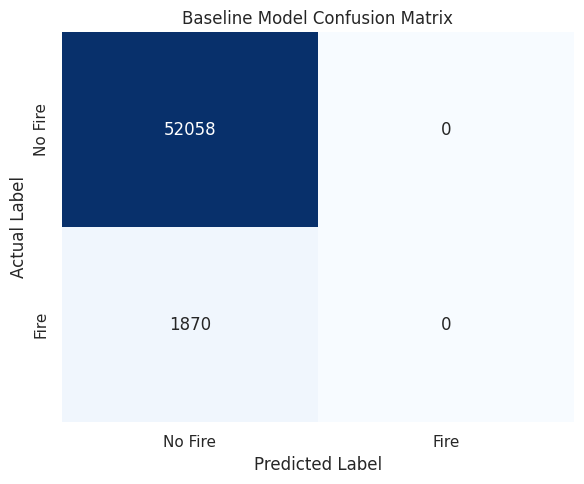

Baseline Model Results
----------------------
pos_weight: N/A
Threshold: N/A
Accuracy: 0.965
Precision: 0.000
Recall: 0.000
F1 Score: 0.000
ROC-AUC: 0.500
PR-AUC: 0.035
PR-AUC / naive: 1.00x

TP: 0
FP: 0
FN: 1870
TN: 52058


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Test labels
test_data = location_model_data[
    location_model_data["year"] >= 2022
].copy()

y_test = test_data["fire"]

# Always predict no fire
baseline_predictions = np.zeros(len(y_test), dtype=int)
baseline_probability = np.zeros(len(y_test))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    baseline_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Fire", "Fire"],
    yticklabels=["No Fire", "Fire"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Baseline Model Confusion Matrix")
plt.tight_layout()
plt.show()

# Calculate metrics
accuracy = accuracy_score(y_test, baseline_predictions)
precision = precision_score(
    y_test,
    baseline_predictions,
    zero_division=0
)
recall = recall_score(
    y_test,
    baseline_predictions,
    zero_division=0
)
f1 = f1_score(
    y_test,
    baseline_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, baseline_probability)
pr_auc = average_precision_score(y_test, baseline_probability)

# Naive PR-AUC equals the fire prevalence
naive_pr_auc = y_test.mean()
pr_auc_ratio = pr_auc / naive_pr_auc

# Print all results
print("Baseline Model Results")
print("----------------------")
print("pos_weight:", "N/A")
print("Threshold:", "N/A")
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")
print(f"PR-AUC / naive: {pr_auc_ratio:.2f}x")
print()
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

# Unoptimized Logistic Regression Model

In [ ]:
import numpy as np

RAP_FEATURES = [
    "ann_forb_grass",
    "peren_forb_grass",
    "shrub",
    "tree",
    "litter"
]

# Features used by the model
model_features = RAP_FEATURES.copy()

# Convert RAP -99 values and other negative values to NaN
location_model_data[RAP_FEATURES] = (
    location_model_data[RAP_FEATURES]
    .where(location_model_data[RAP_FEATURES] >= 0, np.nan)
)

# Remove rows missing any predictor or the fire response
location_model_data = (
    location_model_data
    .dropna(subset=model_features + ["fire"])
    .copy()
)

In [ ]:
numeric_features = [
    'tmmx_previous_7_day_mean_c',
    'tmmn_previous_7_day_mean_c',
    'rain_previous_90_days_mm',
    'wind_previous_3_day_max',
    'rmin_previous_7_day_mean',
    'srad_previous_7_day_mean',

    'ann_forb_grass',
    'peren_forb_grass',
    'tree',
    'litter',
    'bare_ground'
]

categorical_features = [
    'Seed_Zone'
]

model_features = numeric_features + categorical_features

In [ ]:
location_model_data = location_model_data.dropna(
    subset=model_features + ['fire']
).copy()

location_model_data['Seed_Zone'] = (
    location_model_data['Seed_Zone'].astype(str)
)

print(location_model_data.shape)
print(location_model_data['fire'].value_counts())

(350532, 20)
fire
0    301044
1     49488
Name: count, dtype: int64


In [ ]:
# Training data: before 2019
train_data = location_model_data[
    location_model_data["year"] < 2019
].copy()

# Validation data: 2019–2021
val_data = location_model_data[
    location_model_data["year"].between(2019, 2021)
].copy()

# Test data: 2022 and later
test_data = location_model_data[
    location_model_data["year"] >= 2022
].copy()


# Separate predictors and response
X_train = train_data[model_features]
y_train = train_data["fire"]

X_val = val_data[model_features]
y_val = val_data["fire"]

X_test = test_data[model_features]
y_test = test_data["fire"]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            StandardScaler(),
            numeric_features
        ),
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ),
            categorical_features
        )
    ]
)

location_logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'logistic',
            LogisticRegression(
                max_iter=2000,
                solver='lbfgs'
            )
        )
    ]
)

location_logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['tmmx_previous_7_day_mean_c',
                                                   'tmmn_previous_7_day_mean_c',
                                                   'rain_previous_90_days_mm',
                                                   'wind_previous_3_day_max',
                                                   'rmin_previous_7_day_mean',
                                                   'srad_previous_7_day_mean',
                                                   'ann_forb_grass',
                                                   'peren_forb_grass', 'tree',
                                                   'litter', 'bare_ground']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Seed_Zone'])])),
                ('logistic', LogisticRegression(max_iter=2000))])

In [ ]:
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

test_prediction = (
    test_probability >= .5
).astype(int)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, test_probability)
)

print(
    "Average Precision:",
    average_precision_score(y_test, test_probability)
)

print(
    classification_report(
        y_test,
        test_prediction,
        zero_division=0
    )
)

ROC-AUC: 0.750422225477424
Average Precision: 0.08021411360036478
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     52058
           1       0.09      0.03      0.05      1870

    accuracy                           0.96     53928
   macro avg       0.53      0.51      0.51     53928
weighted avg       0.94      0.96      0.95     53928



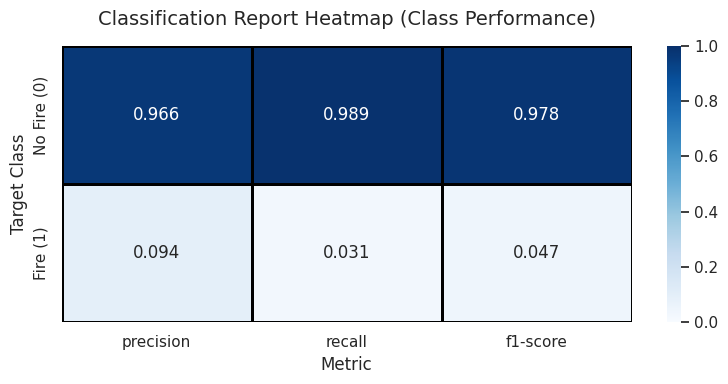

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Generate classification report dictionary
report_dict = classification_report(
    y_test,
    test_prediction,
    zero_division=0,
    output_dict=True
)

# 2. Extract metrics for classes and convert to DataFrame
# We exclude 'accuracy', 'macro avg', and 'weighted avg' for a focused class-level comparison
classes = ['0', '1']
metrics = ['precision', 'recall', 'f1-score']

report_data = {
    metric: [report_dict[cls][metric] for cls in classes]
    for metric in metrics
}

report_df = pd.DataFrame(report_data, index=['No Fire (0)', 'Fire (1)'])

# 3. Plot the heatmap
plt.figure(figsize=(8, 4))
sns.set_theme(style="white")

ax = sns.heatmap(
    report_df,
    annot=True,
    cmap="Blues",
    fmt=".3f",
    cbar=True,
    linewidths=1,
    linecolor='black',
    vmin=0,
    vmax=1
)

plt.title('Classification Report Heatmap (Class Performance)', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tick_params(axis='both', which='major', labelsize=11)
plt.tight_layout()
plt.show()

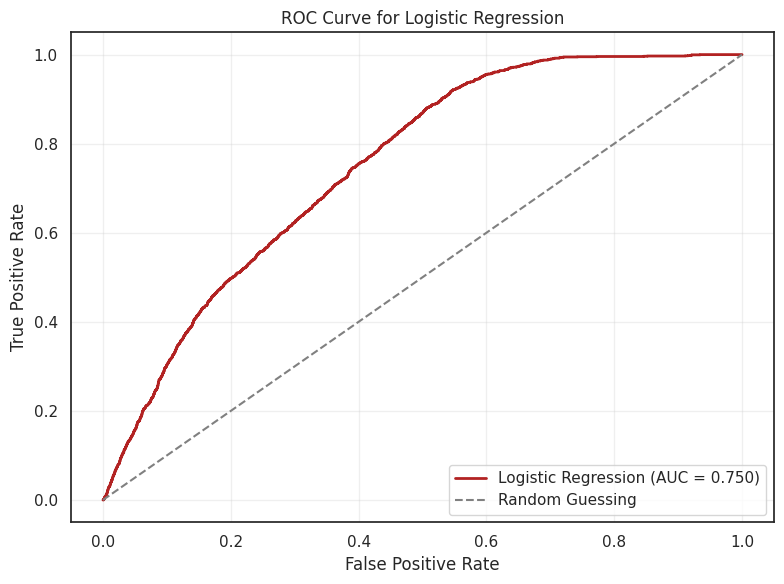

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the fire class
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

# Calculate ROC curve and AUC
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test,
    test_probability
)

roc_auc = roc_auc_score(
    y_test,
    test_probability
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="firebrick",
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

# Random guessing reference line
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

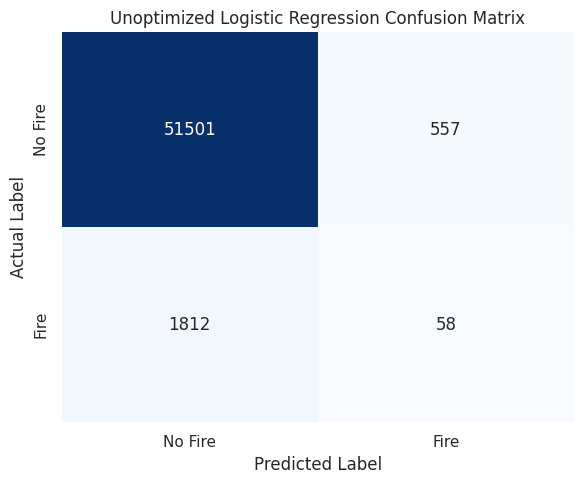

Unoptimized Logistic Regression Results
----------------------------------------
pos_weight: N/A
Threshold: 0.5
Accuracy: 0.956
Precision: 0.094
Recall: 0.031
F1 Score: 0.047
ROC-AUC: 0.750
PR-AUC: 0.080
PR-AUC / naive: 2.31x

TP: 58
FP: 557
FN: 1812
TN: 51501


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Model settings
threshold = 0.50

# Predict probabilities and classifications
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

test_prediction = (
    test_probability >= threshold
).astype(int)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    test_prediction,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Fire", "Fire"],
    yticklabels=["No Fire", "Fire"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Unoptimized Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

# Calculate metrics
accuracy = accuracy_score(y_test, test_prediction)
precision = precision_score(
    y_test,
    test_prediction,
    zero_division=0
)
recall = recall_score(
    y_test,
    test_prediction,
    zero_division=0
)
f1 = f1_score(
    y_test,
    test_prediction,
    zero_division=0
)
roc_auc = roc_auc_score(y_test, test_probability)
pr_auc = average_precision_score(y_test, test_probability)

# Naive PR-AUC equals the fire prevalence
naive_pr_auc = y_test.mean()
pr_auc_ratio = pr_auc / naive_pr_auc

# Print all results
print("Unoptimized Logistic Regression Results")
print("----------------------------------------")
print("pos_weight:", "N/A")
print("Threshold:", threshold)
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")
print(f"PR-AUC / naive: {pr_auc_ratio:.2f}x")
print()
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

# Optimized Logistic Regression

In [ ]:
numeric_features = [
    'tmmx_previous_7_day_mean_c',
    'tmmn_previous_7_day_mean_c',
    'rain_previous_90_days_mm',
    'wind_previous_3_day_max',
    'rmin_previous_7_day_mean',
    'srad_previous_7_day_mean',

    'ann_forb_grass',
    'peren_forb_grass',
    'tree',
    'litter',
    'bare_ground'
]

categorical_features = [
    'Seed_Zone'
]

model_features = numeric_features + categorical_features

In [ ]:
location_model_data = location_model_data.dropna(
    subset=model_features + ['fire']
).copy()

location_model_data['Seed_Zone'] = (
    location_model_data['Seed_Zone'].astype(str)
)

print(location_model_data.shape)
print(location_model_data['fire'].value_counts())

(350532, 20)
fire
0    301044
1     49488
Name: count, dtype: int64


In [ ]:
# Training data: before 2019
train_data = location_model_data[
    location_model_data["year"] < 2019
].copy()

# Validation data: 2019–2021
val_data = location_model_data[
    location_model_data["year"].between(2019, 2021)
].copy()

# Test data: 2022 and later
test_data = location_model_data[
    location_model_data["year"] >= 2022
].copy()


# Separate predictors and response
X_train = train_data[model_features]
y_train = train_data["fire"]

X_val = val_data[model_features]
y_val = val_data["fire"]

X_test = test_data[model_features]
y_test = test_data["fire"]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            StandardScaler(),
            numeric_features
        ),
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ),
            categorical_features
        )
    ]
)

location_logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'logistic',
            LogisticRegression(
                C=100,
                max_iter=2000,
                solver='lbfgs',
                class_weight='balanced',
                penalty='l2'
            )
        )
    ]
)

location_logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['tmmx_previous_7_day_mean_c',
                                                   'tmmn_previous_7_day_mean_c',
                                                   'rain_previous_90_days_mm',
                                                   'wind_previous_3_day_max',
                                                   'rmin_previous_7_day_mean',
                                                   'srad_previous_7_day_mean',
                                                   'ann_forb_grass',
                                                   'peren_forb_grass', 'tree',
                                                   'litter', 'bare_ground']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Seed_Zone'])])),
                ('logistic',
                 LogisticRegression(C=100, class_weight='balanced',
                                    max_iter=2000))])

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

# Predict probabilities on the validation set
val_probability = (
    location_logistic_model
    .predict_proba(X_val)[:, 1]
)

# Test different probability thresholds
thresholds = np.arange(0.01, 1.00, 0.01)

validation_f1_scores = []

for threshold in thresholds:
    val_prediction = (
        val_probability >= threshold
    ).astype(int)

    validation_f1_scores.append(
        f1_score(
            y_val,
            val_prediction,
            zero_division=0
        )
    )

# Find the threshold with the highest validation F1 score
best_index = np.argmax(validation_f1_scores)

best_threshold = thresholds[best_index]
best_validation_f1 = validation_f1_scores[best_index]

print("Best validation probability threshold:", best_threshold)
print("Best validation F1 score:", best_validation_f1)

Best validation probability threshold: 0.6
Best validation F1 score: 0.20573622402890696


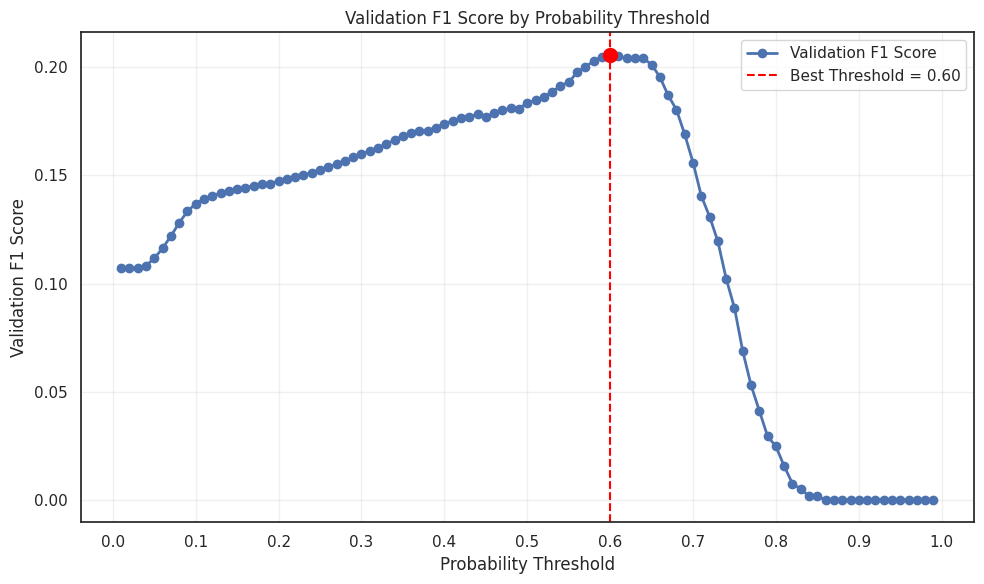

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    validation_f1_scores,
    marker="o",
    linewidth=2,
    label="Validation F1 Score"
)

# Mark the best threshold
plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.scatter(
    best_threshold,
    best_validation_f1,
    color="red",
    s=100,
    zorder=5
)

plt.title("Validation F1 Score by Probability Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Validation F1 Score")
plt.xticks(np.arange(0, 1.1, 0.1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Table Showing Optimizaiton

In [ ]:
# Round thresholds to avoid floating-point matching issues
optimization_table["Probability Threshold"] = (
    optimization_table["Probability Threshold"].round(2)
)

# Keep only thresholds 0.10, 0.20, 0.30, ..., 1.00
optimization_table = optimization_table[
    optimization_table["Probability Threshold"].isin(
        np.arange(0.10, 1.01, 0.10).round(2)
    )
].sort_values("Probability Threshold")

display(optimization_table)

,Probability Threshold,Validation F1 Score,Best Threshold
61,0.1,0.136886,False
50,0.2,0.147384,False
39,0.3,0.159662,False
28,0.4,0.173779,False
17,0.5,0.183578,False
0,0.6,0.205736,True
42,0.7,0.155894,False
79,0.8,0.024750,False
89,0.9,0.000000,False


In [ ]:
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

test_prediction = (
    test_probability >= best_threshold
).astype(int)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, test_probability)
)

print(
    "Average Precision:",
    average_precision_score(y_test, test_probability)
)

print(
    classification_report(
        y_test,
        test_prediction,
        zero_division=0
    )
)

ROC-AUC: 0.7496116528191612
Average Precision: 0.08063566352191671
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     52058
           1       0.08      0.49      0.14      1870

    accuracy                           0.79     53928
   macro avg       0.53      0.65      0.51     53928
weighted avg       0.95      0.79      0.85     53928



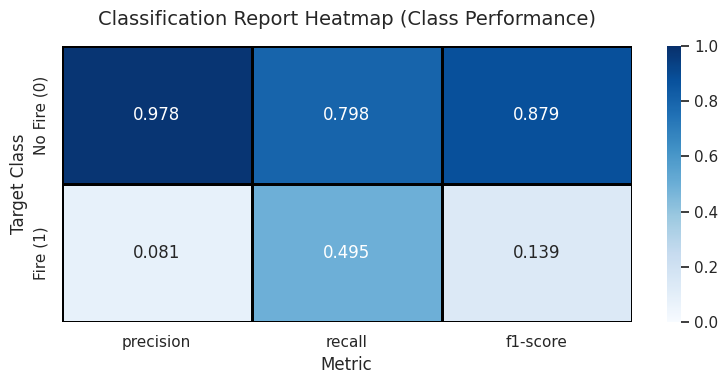

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Generate classification report dictionary
report_dict = classification_report(
    y_test,
    test_prediction,
    zero_division=0,
    output_dict=True
)

# 2. Extract metrics for classes and convert to DataFrame
# We exclude 'accuracy', 'macro avg', and 'weighted avg' for a focused class-level comparison
classes = ['0', '1']
metrics = ['precision', 'recall', 'f1-score']

report_data = {
    metric: [report_dict[cls][metric] for cls in classes]
    for metric in metrics
}

report_df = pd.DataFrame(report_data, index=['No Fire (0)', 'Fire (1)'])

# 3. Plot the heatmap
plt.figure(figsize=(8, 4))
sns.set_theme(style="white")

ax = sns.heatmap(
    report_df,
    annot=True,
    cmap="Blues",
    fmt=".3f",
    cbar=True,
    linewidths=1,
    linecolor='black',
    vmin=0,
    vmax=1
)

plt.title('Classification Report Heatmap (Class Performance)', fontsize=14, pad=15)
plt.xlabel('Metric', fontsize=12)
plt.ylabel('Target Class', fontsize=12)
plt.tick_params(axis='both', which='major', labelsize=11)
plt.tight_layout()
plt.show()

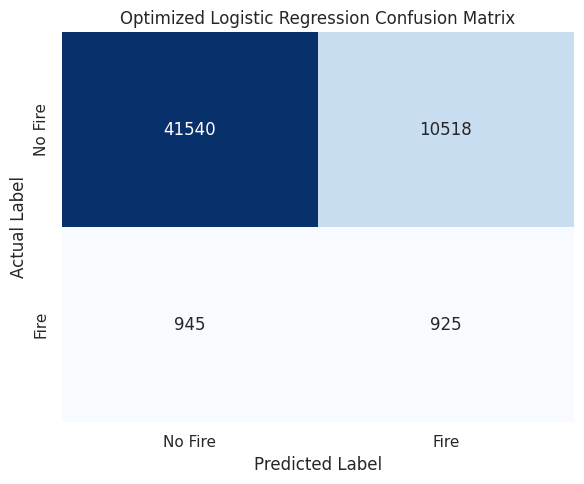

Optimized Logistic Regression Results
-------------------------------------
pos_weight: 4.651
Threshold: 0.60
Accuracy: 0.787
Precision: 0.081
Recall: 0.495
F1 Score: 0.139
ROC-AUC: 0.750
PR-AUC: 0.081
PR-AUC / naive: 2.33x

TP: 925
FP: 10518
FN: 945
TN: 41540


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Model settings
threshold = best_threshold

# Calculate the effective positive-class weight used by "balanced"
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

pos_weight = negative_count / positive_count

# Predict probabilities and classifications
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

test_prediction = (
    test_probability >= threshold
).astype(int)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    test_prediction,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Fire", "Fire"],
    yticklabels=["No Fire", "Fire"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Optimized Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

# Calculate metrics
accuracy = accuracy_score(y_test, test_prediction)
precision = precision_score(y_test, test_prediction, zero_division=0)
recall = recall_score(y_test, test_prediction, zero_division=0)
f1 = f1_score(y_test, test_prediction, zero_division=0)
roc_auc = roc_auc_score(y_test, test_probability)
pr_auc = average_precision_score(y_test, test_probability)

# Naive PR-AUC equals the fire prevalence
naive_pr_auc = y_test.mean()
pr_auc_ratio = pr_auc / naive_pr_auc

# Print all results
print("Optimized Logistic Regression Results")
print("-------------------------------------")
print(f"pos_weight: {pos_weight:.3f}")
print(f"Threshold: {threshold:.2f}")
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")
print(f"PR-AUC / naive: {pr_auc_ratio:.2f}x")
print()
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

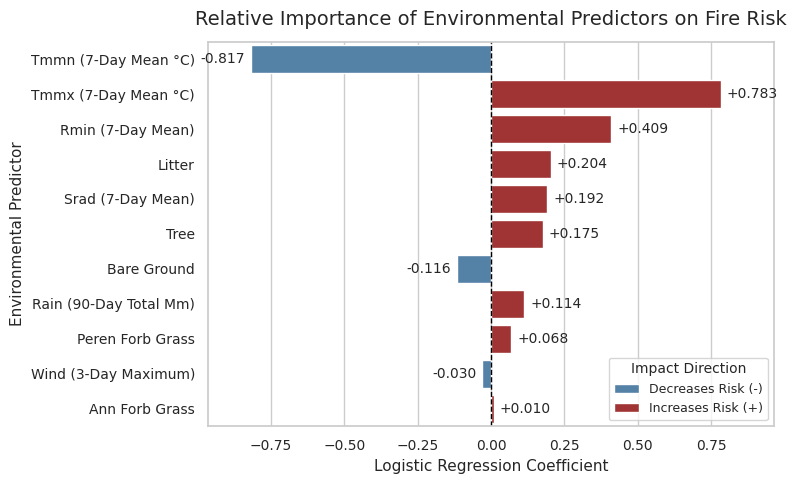

,Clean_Feature,Coefficient
0,Tmmx (7-Day Mean °C),0.783293
1,Rmin (7-Day Mean),0.408769
2,Litter,0.204225
3,Srad (7-Day Mean),0.192174
4,Tree,0.175398
5,Rain (90-Day Total Mm),0.113749
6,Peren Forb Grass,0.068442
7,Ann Forb Grass,0.009573
8,Wind (3-Day Maximum),-0.030361
9,Bare Ground,-0.116109


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrieve the preprocessor and logistic regression steps
preprocessor_step = final_location_model.named_steps["preprocessor"]
model_step = final_location_model.named_steps["logistic"]

# 2. Get feature names after preprocessing
numeric_names = numeric_features

cat_encoder = preprocessor_step.named_transformers_["categorical"]

if hasattr(cat_encoder, "get_feature_names_out"):
    categorical_names = list(
        cat_encoder.get_feature_names_out(categorical_features)
    )
else:
    categorical_names = [
        f"Seed_Zone_{cat}"
        for cat in cat_encoder.categories_[0][1:]
    ]

all_transformed_features = numeric_names + categorical_names

# 3. Create coefficient DataFrame
coefficients = model_step.coef_[0]

feature_importance_df = pd.DataFrame({
    "Feature": all_transformed_features,
    "Coefficient": coefficients
})

# Keep only environmental predictors
environmental_importance = feature_importance_df[
    feature_importance_df["Feature"].isin(numeric_features)
].copy()

# Sort from smallest to largest for horizontal bar plot
environmental_importance["Abs_Coefficient"] = (
    environmental_importance["Coefficient"].abs()
)

environmental_importance = environmental_importance.sort_values(
    by="Abs_Coefficient",
    ascending=False
).reset_index(drop=True)

# 4. Format feature names
environmental_importance["Clean_Feature"] = (
    environmental_importance["Feature"]
    .str.replace(
        "_previous_7_day_mean_c",
        " (7-Day Mean °C)",
        regex=False
    )
    .str.replace(
        "_previous_90_days_mm",
        " (90-Day Total mm)",
        regex=False
    )
    .str.replace(
        "_previous_3_day_max",
        " (3-Day Maximum)",
        regex=False
    )
    .str.replace(
        "_previous_7_day_mean",
        " (7-Day Mean)",
        regex=False
    )
    .str.replace("_", " ", regex=False)
    .str.title()
)

# 5. Label coefficient direction
environmental_importance["Direction"] = np.where(
    environmental_importance["Coefficient"] >= 0,
    "Increases Risk (+)",
    "Decreases Risk (-)"
)

# 6. Create smaller figure with larger fonts
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=environmental_importance,
    x="Coefficient",
    y="Clean_Feature",
    hue="Direction",
    dodge=False,
    palette={
        "Increases Risk (+)": "firebrick",
        "Decreases Risk (-)": "steelblue"
    },
    ax=ax
)

# Add coefficient labels next to each bar
max_coefficient = environmental_importance["Coefficient"].abs().max()
label_offset = max_coefficient * 0.025

for y_position, coefficient in enumerate(
    environmental_importance["Coefficient"]
):
    if coefficient >= 0:
        ax.text(
            coefficient + label_offset,
            y_position,
            f"{coefficient:+.3f}",
            va="center",
            ha="left",
            fontsize=10
        )
    else:
        ax.text(
            coefficient - label_offset,
            y_position,
            f"{coefficient:+.3f}",
            va="center",
            ha="right",
            fontsize=10
        )

# Add extra horizontal space for coefficient labels
ax.set_xlim(
    -max_coefficient * 1.18,
    max_coefficient * 1.18
)

# Formatting
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Relative Importance of Environmental Predictors on Fire Risk",
    fontsize=14,
    pad=12
)

ax.set_xlabel(
    "Logistic Regression Coefficient",
    fontsize=11
)

ax.set_ylabel(
    "Environmental Predictor",
    fontsize=11
)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    title="Impact Direction",
    fontsize=9,
    title_fontsize=10,
    loc="lower right"
)

plt.tight_layout()
plt.show()

# Display sorted coefficient values
display(
    environmental_importance[
        ["Clean_Feature", "Coefficient"]
    ]
    .sort_values(
        by="Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

In [ ]:
X_all = location_model_data[model_features]
y_all = location_model_data['fire']

final_location_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'logistic',
            LogisticRegression(
                max_iter=2000,
                solver='lbfgs',
                class_weight='balanced'
            )
        )
    ]
)

final_location_model.fit(X_all, y_all)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['tmmx_previous_7_day_mean_c',
                                                   'tmmn_previous_7_day_mean_c',
                                                   'rain_previous_90_days_mm',
                                                   'wind_previous_3_day_max',
                                                   'rmin_previous_7_day_mean',
                                                   'srad_previous_7_day_mean',
                                                   'ann_forb_grass',
                                                   'peren_forb_grass', 'tree',
                                                   'litter', 'bare_ground']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Seed_Zone'])])),
                ('logistic',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [ ]:
location_model_data['risk_score'] = (
    final_location_model
    .predict_proba(X_all)[:, 1]
)

location_model_data['risk_level'] = pd.cut(
    location_model_data['risk_score'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1],
    labels=[
        'Very Low',
        'Low',
        'Moderate',
        'High',
        'Very High'
    ],
    include_lowest=True
)

You can change MAP_YEAR to any year to get the given map of our prediction based on each given place on the grid for each year.

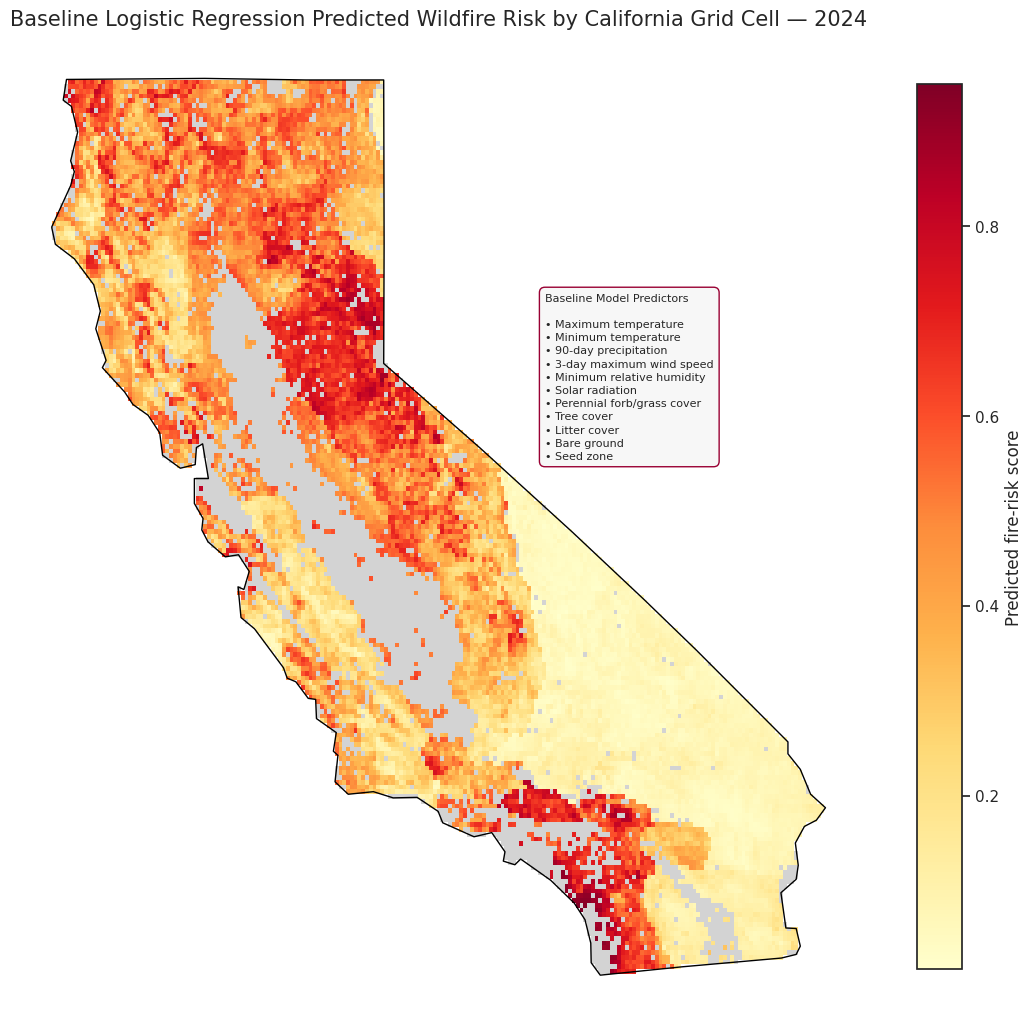

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# Choose the year to map
MAP_YEAR = 2024

# Get risk scores for that year
map_data = location_model_data[
    location_model_data['year'] == MAP_YEAR
][['cell_id', 'risk_score']].copy()

# Attach risk scores to every California grid cell
risk_cells = california_grid.merge(
    map_data,
    on='cell_id',
    how='left'
)

# California boundary
california_map = california_boundary.to_crs('EPSG:4326')

# Use the observed score range for better color contrast
vmin = risk_cells['risk_score'].min()
vmax = risk_cells['risk_score'].max()

fig, ax = plt.subplots(figsize=(11, 13))

# Plot grid-cell risk scores
risk_cells.plot(
    ax=ax,
    column='risk_score',
    cmap='YlOrRd',
    vmin=vmin,
    vmax=vmax,
    edgecolor='none',
    legend=True,
    legend_kwds={
        'label': 'Predicted fire-risk score',
        'shrink': 0.7
    },
    missing_kwds={
        'color': 'lightgrey',
        'label': 'Missing predictors'
    }
)

# Add California outline
california_map.boundary.plot(
    ax=ax,
    color='black',
    linewidth=1
)

ax.set_title(
    f'Baseline Logistic Regression Predicted Wildfire Risk by California Grid Cell — {MAP_YEAR}',
    fontsize=15
)
baseline_predictors = [
    "Maximum temperature",
    "Minimum temperature",
    "90-day precipitation",
    "3-day maximum wind speed",
    "Minimum relative humidity",
    "Solar radiation",
    "Perennial forb/grass cover",
    "Tree cover",
    "Litter cover",
    "Bare ground",
    "Seed zone"
]

predictor_text = (
    "Baseline Model Predictors\n\n"
    + "\n".join(f"• {predictor}" for predictor in baseline_predictors)
)

fig.text(
    0.50,                 # Horizontal position: move left/right
    0.68,                 # Vertical position: move up/down
    predictor_text,
    ha="left",
    va="top",
    fontsize=8,
    linespacing=1.4,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f7f7f7",
        edgecolor="#990033",
        linewidth=1
    )
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

### Feature Importance Analysis

To understand which environmental and spatial predictors drive our wildfire risk predictions, we can extract the coefficients from our trained final model. Since our numerical predictors were normalized using `StandardScaler` inside the pipeline, the magnitude of their coefficients directly represents their relative importance and relationship with fire risk.

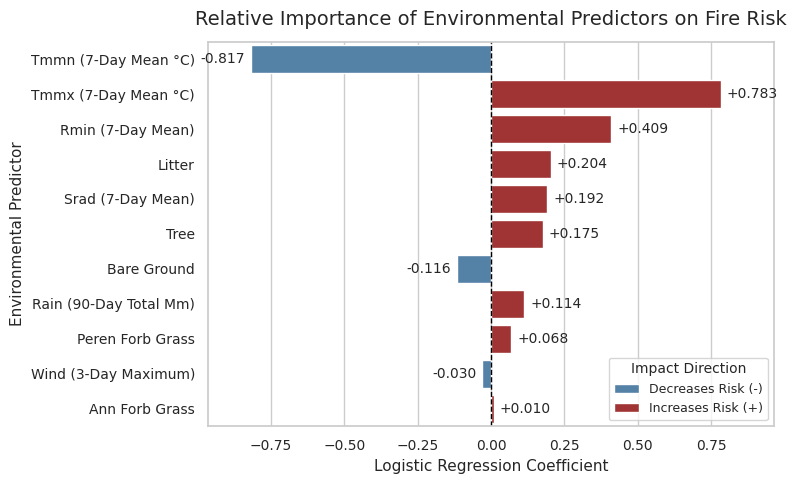

,Clean_Feature,Coefficient
0,Tmmx (7-Day Mean °C),0.783293
1,Rmin (7-Day Mean),0.408769
2,Litter,0.204225
3,Srad (7-Day Mean),0.192174
4,Tree,0.175398
5,Rain (90-Day Total Mm),0.113749
6,Peren Forb Grass,0.068442
7,Ann Forb Grass,0.009573
8,Wind (3-Day Maximum),-0.030361
9,Bare Ground,-0.116109


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrieve the preprocessor and logistic regression steps
preprocessor_step = final_location_model.named_steps["preprocessor"]
model_step = final_location_model.named_steps["logistic"]

# 2. Get feature names after preprocessing
numeric_names = numeric_features

cat_encoder = preprocessor_step.named_transformers_["categorical"]

if hasattr(cat_encoder, "get_feature_names_out"):
    categorical_names = list(
        cat_encoder.get_feature_names_out(categorical_features)
    )
else:
    categorical_names = [
        f"Seed_Zone_{cat}"
        for cat in cat_encoder.categories_[0][1:]
    ]

all_transformed_features = numeric_names + categorical_names

# 3. Create coefficient DataFrame
coefficients = model_step.coef_[0]

feature_importance_df = pd.DataFrame({
    "Feature": all_transformed_features,
    "Coefficient": coefficients
})

# Keep only environmental predictors
environmental_importance = feature_importance_df[
    feature_importance_df["Feature"].isin(numeric_features)
].copy()

# Sort from smallest to largest for horizontal bar plot
environmental_importance["Abs_Coefficient"] = (
    environmental_importance["Coefficient"].abs()
)

environmental_importance = environmental_importance.sort_values(
    by="Abs_Coefficient",
    ascending=False
).reset_index(drop=True)

# 4. Format feature names
environmental_importance["Clean_Feature"] = (
    environmental_importance["Feature"]
    .str.replace(
        "_previous_7_day_mean_c",
        " (7-Day Mean °C)",
        regex=False
    )
    .str.replace(
        "_previous_90_days_mm",
        " (90-Day Total mm)",
        regex=False
    )
    .str.replace(
        "_previous_3_day_max",
        " (3-Day Maximum)",
        regex=False
    )
    .str.replace(
        "_previous_7_day_mean",
        " (7-Day Mean)",
        regex=False
    )
    .str.replace("_", " ", regex=False)
    .str.title()
)

# 5. Label coefficient direction
environmental_importance["Direction"] = np.where(
    environmental_importance["Coefficient"] >= 0,
    "Increases Risk (+)",
    "Decreases Risk (-)"
)

# 6. Create smaller figure with larger fonts
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=environmental_importance,
    x="Coefficient",
    y="Clean_Feature",
    hue="Direction",
    dodge=False,
    palette={
        "Increases Risk (+)": "firebrick",
        "Decreases Risk (-)": "steelblue"
    },
    ax=ax
)

# Add coefficient labels next to each bar
max_coefficient = environmental_importance["Coefficient"].abs().max()
label_offset = max_coefficient * 0.025

for y_position, coefficient in enumerate(
    environmental_importance["Coefficient"]
):
    if coefficient >= 0:
        ax.text(
            coefficient + label_offset,
            y_position,
            f"{coefficient:+.3f}",
            va="center",
            ha="left",
            fontsize=10
        )
    else:
        ax.text(
            coefficient - label_offset,
            y_position,
            f"{coefficient:+.3f}",
            va="center",
            ha="right",
            fontsize=10
        )

# Add extra horizontal space for coefficient labels
ax.set_xlim(
    -max_coefficient * 1.18,
    max_coefficient * 1.18
)

# Formatting
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Relative Importance of Environmental Predictors on Fire Risk",
    fontsize=14,
    pad=12
)

ax.set_xlabel(
    "Logistic Regression Coefficient",
    fontsize=11
)

ax.set_ylabel(
    "Environmental Predictor",
    fontsize=11
)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    title="Impact Direction",
    fontsize=9,
    title_fontsize=10,
    loc="lower right"
)

plt.tight_layout()
plt.show()

# Display sorted coefficient values
display(
    environmental_importance[
        ["Clean_Feature", "Coefficient"]
    ]
    .sort_values(
        by="Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

All the data used is defined by each spot on the grid of a california, each spot reprenseting the entire year.

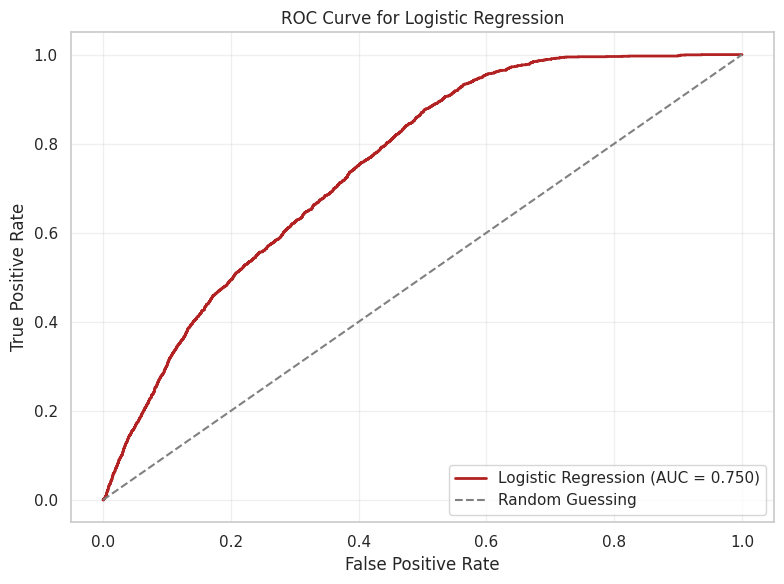

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the fire class
test_probability = (
    location_logistic_model
    .predict_proba(X_test)[:, 1]
)

# Calculate ROC curve and AUC
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test,
    test_probability
)

roc_auc = roc_auc_score(
    y_test,
    test_probability
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="firebrick",
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

# Random guessing reference line
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()